# Self-Supervised Modelling of Honest Compiler Behaviour Detects Unseen Trojans in Quantum Circuits

**Threat model.** A user sends a logical circuit to a third-party transpiler, optimiser or cloud compilation service. The service returns a hardware-native circuit (basis `rz, sx, x, cx`). A malicious service can hide a few extra gates in that circuit. These gates corrupt the output while the circuit still looks like normal compiler output.

**What the notebook does.**
1. Loads public benchmark circuits from **MQT Bench** and **QASMBench**.
2. Simulates an honest compiler. Each circuit is compiled several times with different optimisation levels (1–3), routing (all-to-all or linear topology), seeds and optional dynamical-decoupling padding. These are the benign (clean) samples, and they differ in size and structure without being malicious.
3. Inserts five trojan types into compiled circuits and measures each trojan's impact on the output distribution (total variation distance and Hellinger fidelity).
4. Converts every compiled circuit into a gate-level DAG graph.
5. Compares four structural baselines (including a new re-optimisation residual test) with a GIN graph neural network that localises trojan gates (node level) and uses that localisation to detect trojaned circuits (graph level).
6. Evaluation:
   * **E1** 5-fold cross-validation with whole algorithm families held out, so test algorithms are never seen in training
   * **E2** leave-one-trojan-type-out, so the test trojan type is never seen in training
   * **E3** detection rate against trojan impact (including dormant trojans)
   * **E4** trojan localisation (top-1 / top-5)
   * **E5** detection latency against simulation-based verification
   * **E6** a 2 × 2 realism study (fixed or varied compiler, random or family-held-out split) that explains the gap with prior work
   * **E7** the proposed self-supervised masked gate modelling (MGM) detector, which is trained on clean circuits only; its type-calibrated, size-corrected variant (MGM-C); and the fusion of MGM-C with the supervised GIN-L2D
   * **E8** an adaptive attacker that places trojans to evade each detector, measured with threshold-free AUC across attack budgets of 1 to 32 placements (white-box and transfer), including an ensemble defence

**v6 (revision).** Section 15 adds the experiments requested in peer review: repeated family splits with confidence intervals (R1), unsupervised baselines (R1), ablations (R2), angle-matched and pre-optimisation trojans (R3), a cross-compiler test with tket (R4), CPU latency (R5) and impact analysis from several inputs stratified by trojan type (R6). Sections 0–13 are unchanged apart from the impact-bin edge in section 9, so their results reproduce v5.

**Runtime.** Go to Runtime → Change runtime type → T4 GPU (optional, speeds up E1 and E2). The notebook also runs on CPU.

**Datasets** (both are downloaded or generated by the cells below; you do not need to upload anything):
* MQT Bench: https://github.com/cda-tum/mqt-bench, portal https://www.cda.cit.tum.de/mqtbench/ . Citation: N. Quetschlich, L. Burgholzer, R. Wille, "MQT Bench: Benchmarking Software and Design Automation Tools for Quantum Computing", *Quantum* 7, 1062 (2023).
* QASMBench: https://github.com/pnnl/QASMBench . Citation: A. Li, S. Stein, S. Krishnamoorthy, J. Ang, "QASMBench: A Low-Level Quantum Benchmark Suite for NISQ Evaluation and Simulation", *ACM Transactions on Quantum Computing* 4(2), 2023.

## 0. Setup

In [ ]:
!pip -q install "qiskit==2.5.2" "qiskit-aer==0.17.2" "mqt.bench==2.3.0" torch_geometric pytket
!git clone -q --depth 1 https://github.com/pnnl/QASMBench.git

In [ ]:
import os
import time
import random
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
os.makedirs("results", exist_ok=True)


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass


set_seed(42)

## 1. Load benchmark circuits (MQT Bench and QASMBench)

The code keeps only static unitary circuits: final measurements are removed, and circuits with mid-circuit measurement, reset or classical control flow are dropped. Circuits are also limited to at most 12 qubits so that exact statevector simulation can measure trojan impact. Each circuit is assigned an *algorithm family*, and families are what the cross-validation holds out.

In [ ]:
from qiskit import QuantumCircuit
from mqt.bench import get_benchmark, BenchmarkLevel
from mqt.bench.benchmarks import get_available_benchmark_names

FAMILY_ALIASES = {
    "qftentangled": "qft", "inverseqft": "qft", "dynamic_qft": "qft",
    "qpeexact": "qpe", "qpeinexact": "qpe", "pea": "qpe", "ipea": "qpe", "iqpe": "qpe",
    "vqe_real_amp": "vqe", "vqe_su2": "vqe", "vqe_two_local": "vqe", "vqe_uccsd": "vqe", "variational": "vqe",
    "cat_state": "ghz", "ghz_dynamic": "ghz", "bell": "ghz",
    "deutsch": "dj", "quantumwalks": "qwalk",
    "half_adder": "adder", "full_adder": "adder", "cdkm_ripple_carry_adder": "adder",
    "vbe_ripple_carry_adder": "adder", "draper_qft_adder": "adder", "modular_adder": "adder",
    "rg_qft_multiplier": "multiplier", "hrs_cumulative_multiplier": "multiplier",
    "linearsolver": "hhl",
}


def family_of(name):
    stem = name.split("_n")[0] if "_n" in name and name.split("_n")[-1].isdigit() else name
    return FAMILY_ALIASES.get(stem, stem)


def to_static_unitary(qc, max_qubits=12):
    """Return the circuit without final measurements, or None if it is not a static unitary circuit."""
    try:
        qc = qc.remove_final_measurements(inplace=False)
    except Exception:
        return None
    ops = {inst.operation.name for inst in qc.data}
    if ops & {"measure", "reset", "if_else", "while_loop", "for_loop", "switch_case", "delay"}:
        return None
    if qc.num_qubits < 2 or qc.num_qubits > max_qubits or qc.size() == 0:
        return None
    no_barrier = qc.copy_empty_like()
    for inst in qc.data:
        if inst.operation.name != "barrier":
            no_barrier.append(inst.operation, inst.qubits, inst.clbits)
    return no_barrier


def load_mqt_circuits(sizes=range(3, 11), max_qubits=12):
    rows = []
    for name in get_available_benchmark_names():
        for n in sizes:
            try:
                qc = get_benchmark(name, BenchmarkLevel.INDEP, n)
            except Exception:
                continue
            qc = to_static_unitary(qc, max_qubits)
            if qc is not None:
                rows.append({"name": f"{name}_n{qc.num_qubits}", "family": family_of(name),
                             "source": "MQT Bench", "qc": qc})
    return rows


def load_qasmbench_circuits(root="QASMBench", subsets=("small", "medium"), max_qubits=12):
    rows = []
    for subset in subsets:
        folder = os.path.join(root, subset)
        if not os.path.isdir(folder):
            continue
        for bench in sorted(os.listdir(folder)):
            path = os.path.join(folder, bench, f"{bench}.qasm")
            if not os.path.isfile(path):
                continue
            try:
                qc = QuantumCircuit.from_qasm_file(path)
            except Exception:
                continue
            qc = to_static_unitary(qc, max_qubits)
            if qc is not None:
                rows.append({"name": bench, "family": family_of(bench),
                             "source": "QASMBench", "qc": qc})
    return rows


def deduplicate(rows):
    seen, out = set(), []
    for r in rows:
        key = (r["family"], r["qc"].num_qubits, r["qc"].size(), tuple(sorted(r["qc"].count_ops().items())))
        if key not in seen:
            seen.add(key)
            out.append(r)
    return out


base_circuits = deduplicate(load_mqt_circuits() + load_qasmbench_circuits())
base_df = pd.DataFrame([{"name": r["name"], "family": r["family"], "source": r["source"],
                         "qubits": r["qc"].num_qubits, "gates": r["qc"].size()} for r in base_circuits])
print(f"{len(base_circuits)} base circuits from {base_df.family.nunique()} algorithm families")
base_df.groupby("source").agg(circuits=("name", "count"), families=("family", "nunique"),
                              min_qubits=("qubits", "min"), max_qubits=("qubits", "max"))

220 base circuits from 34 algorithm families


,circuits,families,min_qubits,max_qubits
source,,,,
MQT Bench,187,19,3,10
QASMBench,33,26,2,11


## 2. Honest compiler model (benign variation)

Clean samples are produced by an honest compiler that varies its optimisation level (1–3), topology (all-to-all or linear chain, which forces SWAP routing), seed and, in half of the samples, dynamical-decoupling style `x`–`x` padding. Gate count, depth and gate mix therefore change between clean samples, so a detector cannot flag a circuit simply because it contains extra gates. Level 0 (no optimisation) is excluded because cloud and SDK compilation services always optimise (Qiskit's default is level 2). This is the assumption a reference-free detector relies on: honest output is close to locally optimal, while inserted gates break that local optimality.

In [ ]:
from qiskit import transpile
from qiskit.transpiler import CouplingMap


def honest_compile(qc, rng, basis=("rz", "sx", "x", "cx")):
    opt_level = int(rng.integers(1, 4))
    topology = str(rng.choice(["all_to_all", "linear"]))
    coupling = None if topology == "all_to_all" else CouplingMap.from_line(qc.num_qubits)
    compiled = transpile(qc, basis_gates=list(basis), coupling_map=coupling,
                         optimization_level=opt_level, seed_transpiler=int(rng.integers(0, 10**6)))
    return compiled, opt_level, topology


def rebuild(qc, instructions):
    out = qc.copy_empty_like()
    for op, qargs in instructions:
        out.append(op, qargs)
    return out


def dd_padding(qc, rng, prob=0.5, pairs_per_qubit=(1, 3)):
    """Benign dynamical-decoupling style X-X pairs (identity) placed on random wires."""
    from qiskit.circuit.library import XGate
    instructions = [(inst.operation, list(inst.qubits)) for inst in qc.data]
    if rng.random() >= prob:
        return qc, False
    for q in qc.qubits:
        for _ in range(int(rng.integers(pairs_per_qubit[0], pairs_per_qubit[1] + 1))):
            pos = int(rng.integers(0, len(instructions) + 1))
            instructions[pos:pos] = [(XGate(), [q]), (XGate(), [q])]
    return rebuild(qc, instructions), True

## 3. Trojan library

| Code | Trojan | Inserted gates | Intended effect |
|---|---|---|---|
| T1 | Phase kick | `rz(θ)` on one wire | Shifts interference phases |
| T2 | Superposition leak | `sx` on one wire | Moves amplitude out of the intended basis |
| T3 | Hidden entangler | one extra `cx` | Creates unwanted correlation between two qubits |
| T4 | ZZ camouflage | `cx – rz(θ) – cx` | Conditional phase that looks like normal compiled ZZ blocks |
| T5 | Readout flip | `x` at the end of one wire | Flips a measured bit |

θ is drawn uniformly from ±[π/16, π/2]. Insertion points are random. Every inserted gate is labelled so that the model can learn to localise it.

In [ ]:
from qiskit.circuit.library import RZGate, SXGate, XGate, CXGate

TROJAN_TYPES = ["T1_phase", "T2_superposition", "T3_entangler", "T4_zz_camouflage", "T5_readout_flip"]


def trojan_payload(kind, qubits, rng, angle_range=(np.pi / 16, np.pi / 2)):
    theta = float(rng.uniform(*angle_range) * rng.choice([-1, 1]))
    a, b = rng.choice(len(qubits), size=2, replace=False)
    qa, qb = qubits[a], qubits[b]
    if kind == "T1_phase":
        return [(RZGate(theta), [qa])]
    if kind == "T2_superposition":
        return [(SXGate(), [qa])]
    if kind == "T3_entangler":
        return [(CXGate(), [qa, qb])]
    if kind == "T4_zz_camouflage":
        return [(CXGate(), [qa, qb]), (RZGate(theta), [qb]), (CXGate(), [qa, qb])]
    if kind == "T5_readout_flip":
        return [(XGate(), [qa])]
    raise ValueError(kind)


def insert_trojan(qc, kind, rng):
    """Return (trojaned circuit, per-gate boolean mask marking trojan gates)."""
    instructions = [(inst.operation, list(inst.qubits)) for inst in qc.data]
    payload = trojan_payload(kind, qc.qubits, rng)
    pos = len(instructions) if kind == "T5_readout_flip" else int(rng.integers(0, len(instructions) + 1))
    new_instructions = instructions[:pos] + payload + instructions[pos:]
    mask = [False] * pos + [True] * len(payload) + [False] * (len(instructions) - pos)
    return rebuild(qc, new_instructions), np.array(mask)

## 4. Generate the labelled dataset and measure trojan impact

For every base circuit the code generates `n_clean` honest compilations and one trojaned compilation per trojan type, so the dataset is balanced 50/50. Trojan impact is measured against the same compiled circuit before insertion. Both output distributions are computed exactly with statevector simulation, and the simulation time is recorded for E5.

In [ ]:

def output_probabilities(qc):
    return Statevector.from_instruction(qc).probabilities()


def impact(p, q):
    tvd = 0.5 * float(np.abs(p - q).sum())
    hellinger_fid = float(np.sum(np.sqrt(p * q)) ** 2)
    return tvd, hellinger_fid


def build_dataset(base_circuits, n_clean=5, max_gates=1500, seed=42, compile_fn=honest_compile, padding_prob=0.5):
    rng = np.random.default_rng(seed)
    samples = []
    for base_id, base in enumerate(base_circuits):
        plans = ["clean"] * n_clean + TROJAN_TYPES
        for kind in plans:
            compiled, opt_level, topology = compile_fn(base["qc"], rng)
            compiled, padded = dd_padding(compiled, rng, prob=padding_prob)
            if compiled.size() + 3 > max_gates:
                continue
            record = {"base_id": base_id, "name": base["name"], "family": base["family"],
                      "source": base["source"], "opt_level": opt_level, "topology": topology,
                      "dd_padded": padded, "kind": kind, "label": int(kind != "clean"),
                      "tvd": 0.0, "hellinger_fidelity": 1.0, "sim_time_s": np.nan}
            if kind == "clean":
                qc, mask = compiled, np.zeros(compiled.size(), dtype=bool)
                t0 = time.perf_counter()
                output_probabilities(qc)
                record["sim_time_s"] = time.perf_counter() - t0
            else:
                qc, mask = insert_trojan(compiled, kind, rng)
                p_clean = output_probabilities(compiled)
                t0 = time.perf_counter()
                p_troj = output_probabilities(qc)
                record["sim_time_s"] = time.perf_counter() - t0
                record["tvd"], record["hellinger_fidelity"] = impact(p_clean, p_troj)
            record.update({"qc": qc, "mask": mask, "qubits": qc.num_qubits,
                           "gates": qc.size(), "depth": qc.depth()})
            samples.append(record)
        if (base_id + 1) % 25 == 0:
            print(f"  processed {base_id + 1}/{len(base_circuits)} base circuits, {len(samples)} samples")
    return samples


t0 = time.time()
samples = build_dataset(base_circuits)
meta = pd.DataFrame([{k: v for k, v in s.items() if k not in ("qc", "mask")} for s in samples])
print(f"{len(samples)} samples in {time.time() - t0:.0f} s; trojaned share = {meta.label.mean():.2f}")
meta.to_csv("results/dataset_metadata.csv", index=False)

  processed 25/220 base circuits, 250 samples
  processed 50/220 base circuits, 500 samples
  processed 75/220 base circuits, 703 samples
  processed 100/220 base circuits, 949 samples
  processed 125/220 base circuits, 1199 samples
  processed 150/220 base circuits, 1394 samples
  processed 175/220 base circuits, 1639 samples
  processed 200/220 base circuits, 1886 samples
2086 samples in 73 s; trojaned share = 0.50


In [ ]:
table1 = (meta.groupby("source")
          .agg(base_circuits=("base_id", "nunique"), families=("family", "nunique"), samples=("kind", "size"),
               trojaned=("label", "sum"), qubits_min=("qubits", "min"), qubits_max=("qubits", "max"),
               gates_median=("gates", "median"), gates_max=("gates", "max")))
table1.loc["Total"] = [meta.base_id.nunique(), meta.family.nunique(), len(meta), meta.label.sum(),
                       meta.qubits.min(), meta.qubits.max(), meta.gates.median(), meta.gates.max()]
table1.to_csv("results/table1_dataset.csv")
table1

,base_circuits,families,samples,trojaned,qubits_min,qubits_max,gates_median,gates_max
source,,,,,,,,
MQT Bench,178.0,19.0,1759.0,879.0,3.0,10.0,113.0,1473.0
QASMBench,33.0,26.0,327.0,164.0,2.0,11.0,57.0,1493.0
Total,211.0,34.0,2086.0,1043.0,2.0,11.0,101.0,1493.0


In [ ]:
impact_table = (meta[meta.label == 1].groupby("kind")
                .agg(n=("tvd", "size"), tvd_mean=("tvd", "mean"), tvd_median=("tvd", "median"),
                     dormant_share=("tvd", lambda x: float((x < 0.01).mean())),
                     hellinger_mean=("hellinger_fidelity", "mean")).round(4))
impact_table.to_csv("results/table2_trojan_impact.csv")
impact_table

,n,tvd_mean,tvd_median,dormant_share,hellinger_mean
kind,,,,,
T1_phase,208,0.0729,0.0000,0.6250,0.9563
T2_superposition,208,0.3422,0.3778,0.1154,0.7177
T3_entangler,208,0.3058,0.2234,0.3990,0.7095
T4_zz_camouflage,210,0.1122,0.0355,0.4143,0.9230
T5_readout_flip,209,0.6995,0.9041,0.1196,0.3379


## 5. Circuit → gate-level DAG graph

Each gate becomes a node and each qubit wire contributes a directed edge from one gate to the next gate on that wire. Edges are added in both directions for message passing. Node features are:
* one-hot gate type
* sin θ and cos θ of the rotation angle
* normalised position of the gate in the circuit
* normalised position of the gate on its wire
* normalised qubit index
* whether the node is the first or last gate on its wire
* local-canonicality flags: whether an identical gate sits directly before or after it on the same wire (an honest optimiser cancels or merges these), and the length of the run of consecutive single-qubit gates it belongs to (an optimiser collapses such runs into at most one Euler rz–sx–rz–sx–rz block)
* the circuit width

In [ ]:
import torch
from torch_geometric.data import Data

GATE_VOCAB = ["rz", "sx", "x", "cx"]


def gate_angle(op):
    if op.params:
        try:
            return float(op.params[0])
        except (TypeError, ValueError):
            return 0.0
    return 0.0


def circuit_to_graph(qc, mask=None, label=0):
    n_gates, n_qubits = qc.size(), qc.num_qubits
    names = [inst.operation.name for inst in qc.data]
    qubit_lists = [[qc.find_bit(q).index for q in inst.qubits] for inst in qc.data]
    wire_len = np.zeros(n_qubits)
    for qidx in qubit_lists:
        wire_len[qidx] += 1
    prev_on_wire, next_on_wire = [dict() for _ in range(n_gates)], [dict() for _ in range(n_gates)]
    last_on_wire, wire_count = {}, np.zeros(n_qubits)
    src, dst, feats = [], [], []
    for i, qidx in enumerate(qubit_lists):
        for q in qidx:
            if q in last_on_wire:
                j = last_on_wire[q]
                src.append(j)
                dst.append(i)
                prev_on_wire[i][q], next_on_wire[j][q] = j, i
            last_on_wire[q] = i

    def same_gate(i, j):
        return names[i] == names[j] and qubit_lists[i] == qubit_lists[j]

    def one_qubit_run(i):
        if len(qubit_lists[i]) != 1:
            return 0
        q, length, j = qubit_lists[i][0], 1, i
        while q in prev_on_wire[j] and len(qubit_lists[prev_on_wire[j][q]]) == 1:
            j, length = prev_on_wire[j][q], length + 1
        j = i
        while q in next_on_wire[j] and len(qubit_lists[next_on_wire[j][q]]) == 1:
            j, length = next_on_wire[j][q], length + 1
        return length

    for i, (inst, qidx) in enumerate(zip(qc.data, qubit_lists)):
        op = inst.operation
        onehot = [float(op.name == g) for g in GATE_VOCAB] + [float(op.name not in GATE_VOCAB)]
        theta = gate_angle(op)
        wire_count[qidx] += 1
        wire_pos = float(np.mean(wire_count[qidx] / np.maximum(wire_len[qidx], 1)))
        prev_same = float(any(same_gate(i, j) for j in prev_on_wire[i].values()))
        next_same = float(any(same_gate(i, j) for j in next_on_wire[i].values()))
        feats.append(onehot + [np.sin(theta), np.cos(theta), i / max(n_gates - 1, 1), wire_pos,
                               float(np.mean(qidx)) / max(n_qubits - 1, 1),
                               float(len(prev_on_wire[i]) < len(qidx)), float(len(next_on_wire[i]) < len(qidx)),
                               prev_same, next_same, min(one_qubit_run(i), 10) / 5.0, n_qubits / 12.0])
    x = np.array(feats, dtype=np.float32)
    edges = np.array([src + dst, dst + src], dtype=np.int64) if src else np.zeros((2, 0), dtype=np.int64)
    node_y = np.zeros(n_gates, dtype=np.float32) if mask is None else mask.astype(np.float32)
    return Data(x=torch.tensor(x), edge_index=torch.tensor(edges),
                y=torch.tensor([float(label)]), node_y=torch.tensor(node_y))


t0 = time.time()
graphs = [circuit_to_graph(s["qc"], s["mask"], s["label"]) for s in samples]
print(f"{len(graphs)} graphs, node feature dim = {graphs[0].x.shape[1]}, built in {time.time() - t0:.0f} s")

2086 graphs, node feature dim = 16, built in 16 s


## 6. Baseline detectors (structural statistics)

* **B1 Gate-count RF**: counts of each gate, size, depth, width, CX ratio and mean |θ|
* **B2 Wire-bigram RF**: B1 plus a histogram of consecutive gate-type pairs on each wire and an 8-bin histogram of rz angles
* **B3 Wire-bigram HGB**: the B2 features with histogram gradient boosting
* **B4 Idempotence-residual HGB**: B2 features plus the *re-optimisation residual*. The compiled circuit is optimised again (Qiskit level 3, no routing), and the change in size, depth and per-gate counts is recorded. Honest optimised output is close to a fixed point of the optimiser, whereas inserted gates are often merged or cancelled. The same residual vector is also given to the GIN graph head.

In [ ]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier


def gate_count_features(qc):
    counts = qc.count_ops()
    size = max(qc.size(), 1)
    angles = [abs(gate_angle(i.operation)) for i in qc.data if i.operation.name == "rz"]
    return [counts.get(g, 0) for g in GATE_VOCAB] + [size, qc.depth(), qc.num_qubits,
                                                     counts.get("cx", 0) / size,
                                                     float(np.mean(angles)) if angles else 0.0]


def bigram_features(qc, angle_bins=8):
    index = {g: k for k, g in enumerate(GATE_VOCAB)}
    bigrams = np.zeros((len(GATE_VOCAB), len(GATE_VOCAB)))
    last = {}
    for inst in qc.data:
        g = index.get(inst.operation.name)
        for q in inst.qubits:
            if q in last and g is not None and last[q] is not None:
                bigrams[last[q], g] += 1
            last[q] = g
    bigrams = bigrams.flatten() / max(qc.size(), 1)
    angles = [gate_angle(i.operation) % (2 * np.pi) for i in qc.data if i.operation.name == "rz"]
    hist = np.histogram(angles, bins=angle_bins, range=(0, 2 * np.pi))[0] / max(len(angles), 1)
    return gate_count_features(qc) + list(bigrams) + list(hist)


X_counts = np.array([gate_count_features(s["qc"]) for s in samples], dtype=float)
X_bigram = np.array([bigram_features(s["qc"]) for s in samples], dtype=float)
y = meta.label.values
groups = meta.family.values


def make_baselines(seed=42):
    return {
        "B1 Gate-count RF": ("counts", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                              n_jobs=-1, random_state=seed)),
        "B2 Wire-bigram RF": ("bigram", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                               n_jobs=-1, random_state=seed)),
        "B3 Wire-bigram HGB": ("bigram", HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05,
                                                                        random_state=seed)),
        "B4 Idempotence-residual HGB": ("bigram+resid", HistGradientBoostingClassifier(
            max_iter=300, learning_rate=0.05, random_state=seed)),
    }


from qiskit.transpiler import generate_preset_pass_manager

REOPTIMISER = generate_preset_pass_manager(optimization_level=3, basis_gates=GATE_VOCAB)


def reoptimisation_residual(qc):
    reopt = REOPTIMISER.run(qc)
    before, after = qc.count_ops(), reopt.count_ops()
    return [qc.size() - reopt.size(), qc.depth() - reopt.depth()] + \
        [before.get(g, 0) - after.get(g, 0) for g in GATE_VOCAB] + [(qc.size() - reopt.size()) / max(qc.size(), 1)]


t0 = time.time()
X_resid = np.array([reoptimisation_residual(s["qc"]) for s in samples], dtype=float)
print(f"re-optimisation residuals computed in {time.time() - t0:.0f} s")
for g, r in zip(graphs, X_resid):
    g.r = torch.tensor(np.sign(r) * np.log1p(np.abs(r)), dtype=torch.float32).unsqueeze(0)

FEATURE_SETS = {"counts": X_counts, "bigram": X_bigram, "bigram+resid": np.hstack([X_bigram, X_resid])}

re-optimisation residuals computed in 9 s


## 7. Proposed detector: GIN with graph-level detection and node-level localisation

The network has four GIN layers with batch normalisation.
* **Graph head**: mean and max pooling over every layer (jumping knowledge), concatenated with the re-optimisation residual, then an MLP.
* **Node head**: scores every gate as trojan or not (localisation).
* **Loss**: BCE(graph) + λ · weighted BCE(node).

Two detection scores are reported:
* **GIN graph head** (ablation): the graph-head probability alone
* **Proposed GIN-L2D** (localise-then-detect): the mean of the graph-head probability and the highest node score, so a single confidently localised trojan gate is enough to flag the circuit

In [ ]:
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GINConv, global_mean_pool, global_max_pool
from sklearn.metrics import roc_auc_score

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)


def build_gnn(in_dim, r_dim, hidden=64, layers=4, dropout=0.2):
    convs, norms = nn.ModuleList(), nn.ModuleList()
    for layer in range(layers):
        d = in_dim if layer == 0 else hidden
        mlp = nn.Sequential(nn.Linear(d, hidden), nn.ReLU(), nn.Linear(hidden, hidden))
        convs.append(GINConv(mlp, train_eps=True))
        norms.append(nn.BatchNorm1d(hidden))
    jk_dim = hidden * layers
    return nn.ModuleDict({
        "convs": convs, "norms": norms,
        "graph_head": nn.Sequential(nn.Linear(2 * jk_dim + r_dim, hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, 1)),
        "node_head": nn.Sequential(nn.Linear(jk_dim, hidden), nn.ReLU(), nn.Linear(hidden, 1)),
        "dropout": nn.Dropout(dropout),
    })


def gnn_forward(model, batch):
    h, layer_outputs = batch.x, []
    for conv, norm in zip(model["convs"], model["norms"]):
        h = model["dropout"](F.relu(norm(conv(h, batch.edge_index))))
        layer_outputs.append(h)
    h_jk = torch.cat(layer_outputs, dim=1)
    pooled = torch.cat([global_mean_pool(h_jk, batch.batch), global_max_pool(h_jk, batch.batch), batch.r], dim=1)
    return model["graph_head"](pooled).squeeze(-1), model["node_head"](h_jk).squeeze(-1)


def predict_gnn(model, graph_list, batch_size=64):
    """Return graph-head scores, localise-then-detect scores and per-gate scores."""
    model.eval()
    graph_scores, node_scores = [], []
    with torch.no_grad():
        for batch in DataLoader(graph_list, batch_size=batch_size):
            batch = batch.to(DEVICE)
            g, n = gnn_forward(model, batch)
            graph_scores.append(torch.sigmoid(g).cpu())
            node_scores.extend(torch.split(torch.sigmoid(n).cpu(), batch.ptr.diff().cpu().tolist()))
    graph_scores = torch.cat(graph_scores).numpy()
    node_scores = [s.numpy() for s in node_scores]
    l2d_scores = 0.5 * (graph_scores + np.array([s.max() for s in node_scores]))
    return graph_scores, l2d_scores, node_scores


def train_gnn(train_graphs, val_graphs, epochs=40, lr=1e-3, batch_size=32, node_loss_weight=0.5,
              node_pos_weight=20.0, seed=42):
    set_seed(seed)
    model = build_gnn(train_graphs[0].x.shape[1], train_graphs[0].r.shape[1]).to(DEVICE)
    optimiser = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimiser, T_max=epochs)
    pos_weight = torch.tensor([node_pos_weight], device=DEVICE)
    loader = DataLoader(train_graphs, batch_size=batch_size, shuffle=True)
    y_val = np.array([g.y.item() for g in val_graphs])
    best_auc, best_state = -1.0, None
    for epoch in range(epochs):
        model.train()
        for batch in loader:
            batch = batch.to(DEVICE)
            optimiser.zero_grad()
            g_logit, n_logit = gnn_forward(model, batch)
            loss = F.binary_cross_entropy_with_logits(g_logit, batch.y) + node_loss_weight * \
                F.binary_cross_entropy_with_logits(n_logit, batch.node_y, pos_weight=pos_weight)
            loss.backward()
            optimiser.step()
        scheduler.step()
        _, val_scores, _ = predict_gnn(model, val_graphs)
        val_auc = roc_auc_score(y_val, val_scores) if len(set(y_val)) > 1 else 0.0
        if val_auc > best_auc:
            best_auc, best_state = val_auc, {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, best_auc

device: cuda


## 8. E1 Family-held-out 5-fold cross-validation

`GroupKFold` splits on algorithm family, so every circuit of a test family (for example all QFT variants) is unseen during training. Within each training fold, 15% of the families are set aside as a validation set. Every model is trained on the remaining families, and its decision threshold is set on the validation set so that the false-positive rate there is at most 10%. No test data is used to choose thresholds.

In [ ]:
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


def split_validation(train_idx, val_share=0.15, seed=42):
    splitter = GroupShuffleSplit(n_splits=1, test_size=val_share, random_state=seed)
    inner_train, inner_val = next(splitter.split(train_idx, groups=groups[train_idx]))
    return train_idx[inner_train], train_idx[inner_val]


def threshold_at_fpr(val_labels, val_scores, max_fpr=0.10):
    negatives = val_scores[val_labels == 0]
    return float(np.quantile(negatives, 1 - max_fpr)) if len(negatives) else 0.5


def run_models(train_idx, test_idx, fold, gnn_epochs=40, max_fpr=0.10):
    tr, va = split_validation(train_idx, seed=fold)
    rows = []
    for model_name, (feature_key, clf) in make_baselines().items():
        X = FEATURE_SETS[feature_key]
        clf.fit(X[tr], y[tr])
        threshold = threshold_at_fpr(y[va], clf.predict_proba(X[va])[:, 1], max_fpr)
        t0 = time.perf_counter()
        scores = clf.predict_proba(X[test_idx])[:, 1]
        latency = (time.perf_counter() - t0) / len(test_idx)
        rows.append(pd.DataFrame({"fold": fold, "model": model_name, "idx": test_idx, "score": scores,
                                  "threshold": threshold, "latency_s": latency}))
    val_graphs = [graphs[i] for i in va]
    model, val_auc = train_gnn([graphs[i] for i in tr], val_graphs, epochs=gnn_epochs)
    val_graph_scores, val_l2d_scores, _ = predict_gnn(model, val_graphs)
    test_graphs = [graphs[i] for i in test_idx]
    t0 = time.perf_counter()
    graph_scores, l2d_scores, node_scores = predict_gnn(model, test_graphs)
    latency = (time.perf_counter() - t0) / len(test_idx)
    rows.append(pd.DataFrame({"fold": fold, "model": "GIN graph head", "idx": test_idx, "score": graph_scores,
                              "threshold": threshold_at_fpr(y[va], val_graph_scores, max_fpr), "latency_s": latency}))
    rows.append(pd.DataFrame({"fold": fold, "model": "Proposed GIN-L2D", "idx": test_idx, "score": l2d_scores,
                              "threshold": threshold_at_fpr(y[va], val_l2d_scores, max_fpr), "latency_s": latency}))
    return pd.concat(rows), dict(zip(test_idx, node_scores)), val_auc


e1_predictions, e1_node_scores = [], {}
for fold, (train_idx, test_idx) in enumerate(GroupKFold(n_splits=5).split(X_counts, y, groups)):
    t0 = time.time()
    preds, node_scores, val_auc = run_models(train_idx, test_idx, fold)
    e1_predictions.append(preds)
    e1_node_scores.update(node_scores)
    print(f"fold {fold}: test families = {sorted(set(groups[test_idx]))}, "
          f"GNN val AUC = {val_auc:.3f}, {time.time() - t0:.0f} s")
e1 = pd.concat(e1_predictions).reset_index(drop=True)
e1 = e1.merge(meta.reset_index().rename(columns={"index": "idx"}), on="idx")
e1["pred"] = (e1.score >= e1.threshold).astype(int)
e1.to_csv("results/e1_predictions.csv", index=False)

fold 0: test families = ['graphstate', 'grover', 'hs4', 'qec_en', 'toffoli', 'vqe'], GNN val AUC = 0.670, 27 s
fold 1: test families = ['adder', 'bv', 'fredkin', 'ising', 'qnn', 'sat', 'teleportation'], GNN val AUC = 0.681, 25 s
fold 2: test families = ['basis_change', 'bmw_quark_cardinality', 'bmw_quark_copula', 'dj', 'dnn', 'iswap', 'qft'], GNN val AUC = 0.679, 21 s
fold 3: test families = ['ae', 'error_correctiond3', 'multiplier', 'qpe', 'qrng', 'simon', 'wstate'], GNN val AUC = 0.670, 25 s
fold 4: test families = ['basis_trotter', 'ghz', 'hhl', 'lpn', 'qaoa', 'qwalk', 'randomcircuit'], GNN val AUC = 0.706, 24 s


In [ ]:
MODEL_ORDER = ["B1 Gate-count RF", "B2 Wire-bigram RF", "B3 Wire-bigram HGB", "B4 Idempotence-residual HGB",
               "GIN graph head", "Proposed GIN-L2D"]


def fold_metrics(df):
    return pd.Series({"Accuracy": accuracy_score(df.label, df.pred),
                      "Precision": precision_score(df.label, df.pred, zero_division=0),
                      "Recall": recall_score(df.label, df.pred, zero_division=0),
                      "F1": f1_score(df.label, df.pred, zero_division=0),
                      "ROC-AUC": roc_auc_score(df.label, df.score),
                      "FPR": float(((df.pred == 1) & (df.label == 0)).sum() / max((df.label == 0).sum(), 1))})


per_fold = e1.groupby(["model", "fold"]).apply(fold_metrics)
summary = per_fold.groupby("model").agg(["mean", "std"]).reindex(MODEL_ORDER)
table3 = pd.DataFrame({m: summary[m]["mean"].map("{:.3f}".format) + " ± " + summary[m]["std"].map("{:.3f}".format)
                       for m in per_fold.columns})
table3.to_csv("results/table3_main_detection.csv")
table3

,Accuracy,Precision,Recall,F1,ROC-AUC,FPR
model,,,,,,
B1 Gate-count RF,0.511 ± 0.013,0.534 ± 0.050,0.118 ± 0.067,0.188 ± 0.091,0.527 ± 0.019,0.096 ± 0.040
B2 Wire-bigram RF,0.587 ± 0.020,0.696 ± 0.076,0.338 ± 0.101,0.443 ± 0.070,0.614 ± 0.019,0.164 ± 0.116
B3 Wire-bigram HGB,0.579 ± 0.013,0.719 ± 0.087,0.281 ± 0.066,0.396 ± 0.052,0.610 ± 0.028,0.124 ± 0.083
B4 Idempotence-residual HGB,0.616 ± 0.025,0.743 ± 0.059,0.359 ± 0.042,0.482 ± 0.041,0.669 ± 0.024,0.127 ± 0.042
GIN graph head,0.586 ± 0.044,0.711 ± 0.164,0.332 ± 0.133,0.433 ± 0.104,0.634 ± 0.060,0.160 ± 0.119
Proposed GIN-L2D,0.609 ± 0.010,0.766 ± 0.133,0.359 ± 0.123,0.468 ± 0.089,0.689 ± 0.028,0.141 ± 0.120


In [ ]:
table4 = (e1[e1.label == 1].pivot_table(index="kind", columns="model", values="pred", aggfunc="mean")
          [MODEL_ORDER].round(3))
table4.loc["Clean (specificity)"] = (1 - e1[e1.label == 0].groupby("model").pred.mean())[MODEL_ORDER].round(3)
table4.to_csv("results/table4_per_trojan_detection.csv")
table4

model,B1 Gate-count RF,B2 Wire-bigram RF,B3 Wire-bigram HGB,B4 Idempotence-residual HGB,GIN graph head,Proposed GIN-L2D
kind,,,,,,
T1_phase,0.101,0.601,0.572,0.630,0.462,0.495
T2_superposition,0.120,0.312,0.221,0.375,0.298,0.317
T3_entangler,0.125,0.255,0.178,0.188,0.183,0.178
T4_zz_camouflage,0.110,0.243,0.167,0.224,0.371,0.371
T5_readout_flip,0.134,0.282,0.268,0.378,0.344,0.435
Clean (specificity),0.904,0.836,0.876,0.873,0.840,0.858


## 9. E3 Detection against trojan impact

Trojans are binned by total variation distance (TVD). Dormant trojans (TVD < 0.01) do not change the output distribution for the \|0…0⟩ input, so an output-based check cannot see them, but they are still malicious modifications that could activate for other inputs or parameter bindings. Structural detection can still find them.

In [ ]:
IMPACT_BINS = [-0.001, 0.01, 0.1, 0.3, 1.0 + 1e-6]  # top edge includes TVD values that exceed 1.0 by rounding
IMPACT_LABELS = ["dormant (<0.01)", "low (0.01-0.1)", "medium (0.1-0.3)", "high (>0.3)"]
troj = e1[e1.label == 1].copy()
troj["impact_bin"] = pd.cut(troj.tvd, IMPACT_BINS, labels=IMPACT_LABELS)
table5 = troj.pivot_table(index="impact_bin", columns="model", values="pred", aggfunc="mean", observed=False)[MODEL_ORDER].round(3)
table5["n"] = troj[troj.model == MODEL_ORDER[0]].groupby("impact_bin", observed=False).size()
table5.to_csv("results/table5_detection_vs_impact.csv")
table5

model,B1 Gate-count RF,B2 Wire-bigram RF,B3 Wire-bigram HGB,B4 Idempotence-residual HGB,GIN graph head,Proposed GIN-L2D,n
impact_bin,,,,,,,
dormant (<0.01),0.115,0.415,0.367,0.398,0.370,0.404,349
low (0.01-0.1),0.123,0.384,0.356,0.425,0.356,0.315,73
medium (0.1-0.3),0.131,0.297,0.217,0.320,0.360,0.337,175
high (>0.3),0.114,0.287,0.226,0.332,0.287,0.341,446


## 10. E4 Trojan localisation

For each trojaned test circuit, the node head ranks every gate. Hit@k checks whether any true trojan gate appears among the top-k ranked gates. The random-guess expectation is shown for reference.

In [ ]:
def localisation_metrics(indices, node_scores, ks=(1, 5, 10)):
    rows = []
    for i in indices:
        mask, scores = samples[i]["mask"], node_scores[i]
        order = np.argsort(-scores)
        row = {"kind": samples[i]["kind"], "gates": len(mask)}
        for k in ks:
            row[f"Hit@{k}"] = float(mask[order[:k]].any())
            n, m = len(mask), int(mask.sum())
            row[f"Random@{k}"] = 1.0 - np.prod([(n - m - j) / (n - j) for j in range(min(k, n - m))])
        rows.append(row)
    return pd.DataFrame(rows)


trojan_idx = [i for i in e1_node_scores if samples[i]["label"] == 1]
loc = localisation_metrics(trojan_idx, e1_node_scores)
table6 = loc.groupby("kind").mean(numeric_only=True).drop(columns="gates")
table6.loc["All"] = loc.mean(numeric_only=True).drop("gates")
table6 = table6.round(3)
table6.to_csv("results/table6_localisation.csv")
table6

,Hit@1,Random@1,Hit@5,Random@5,Hit@10,Random@10
kind,,,,,,
T1_phase,0.312,0.016,0.587,0.082,0.663,0.155
T2_superposition,0.346,0.018,0.577,0.091,0.716,0.172
T3_entangler,0.149,0.016,0.433,0.079,0.611,0.153
T4_zz_camouflage,0.495,0.047,0.710,0.200,0.819,0.336
T5_readout_flip,0.732,0.017,0.885,0.084,0.933,0.165
All,0.407,0.023,0.639,0.107,0.749,0.196


## 11. E2 Leave-one-trojan-type-out generalisation

For each trojan type, the models are trained on clean samples plus the four other types. They are then tested on unseen families, using clean samples plus the held-out type. A single 80/20 family split is shared by all five runs.

In [ ]:
outer = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=7)
train_all, test_all = next(outer.split(X_counts, y, groups))
loto_rows = []
for held_out in TROJAN_TYPES:
    kinds = meta.kind.values
    train_idx = train_all[kinds[train_all] != held_out]
    test_idx = test_all[np.isin(kinds[test_all], ["clean", held_out])]
    preds, _, _ = run_models(train_idx, test_idx, fold=0)
    preds = preds.merge(meta[["label"]].reset_index().rename(columns={"index": "idx"}), on="idx")
    for model_name, df in preds.groupby("model"):
        loto_rows.append({"held_out": held_out, "model": model_name,
                          "ROC-AUC": roc_auc_score(df.label, df.score),
                          "Recall@val-threshold": float((df[df.label == 1].score >= df.threshold.iloc[0]).mean())})
    print(f"held out {held_out}: done")
table7 = pd.DataFrame(loto_rows).pivot_table(index="held_out", columns="model", values="ROC-AUC")[MODEL_ORDER].round(3)
table7.loc["Mean"] = table7.mean().round(3)
table7.to_csv("results/table7_leave_one_trojan_out_auc.csv")
pd.DataFrame(loto_rows).to_csv("results/e2_loto_full.csv", index=False)
table7

held out T1_phase: done
held out T2_superposition: done
held out T3_entangler: done
held out T4_zz_camouflage: done
held out T5_readout_flip: done


model,B1 Gate-count RF,B2 Wire-bigram RF,B3 Wire-bigram HGB,B4 Idempotence-residual HGB,GIN graph head,Proposed GIN-L2D
held_out,,,,,,
T1_phase,0.542,0.563,0.521,0.612,0.449,0.453
T2_superposition,0.526,0.479,0.468,0.488,0.555,0.544
T3_entangler,0.459,0.480,0.542,0.484,0.500,0.513
T4_zz_camouflage,0.530,0.518,0.522,0.585,0.624,0.580
T5_readout_flip,0.603,0.620,0.607,0.580,0.544,0.546
Mean,0.532,0.532,0.532,0.550,0.534,0.527


## 12. E5 Detection latency against simulation-based verification

Simulation-based verification needs the full output distribution of the compiled circuit, and its cost grows as 2ⁿ. GNN inference cost grows linearly with the number of gates. The table reports both costs per circuit width. Because the benchmark circuits have at most 12 qubits, the exponential gap appears only as a trend within this range.

In [ ]:
gnn_latency = e1[e1.model == "Proposed GIN-L2D"].latency_s.mean()
table8 = meta.groupby("qubits").agg(circuits=("sim_time_s", "size"), sim_ms_mean=("sim_time_s", lambda x: 1000 * x.mean()))
table8["gnn_ms_per_circuit"] = 1000 * gnn_latency
table8["speedup"] = table8.sim_ms_mean / table8.gnn_ms_per_circuit
table8 = table8.round(3)
table8.to_csv("results/table8_latency.csv")
table8

,circuits,sim_ms_mean,gnn_ms_per_circuit,speedup
qubits,,,,
2,50,2.225,0.132,16.873
3,280,1.955,0.132,14.829
4,347,3.832,0.132,29.062
5,247,6.761,0.132,51.285
6,243,7.357,0.132,55.801
7,220,10.066,0.132,76.349
8,240,14.044,0.132,106.527
9,204,16.483,0.132,125.026
10,245,16.801,0.132,127.435


## 13a. Figures (300 dpi PNG in `results/`)

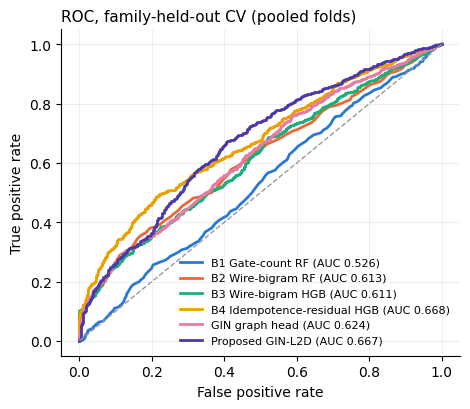

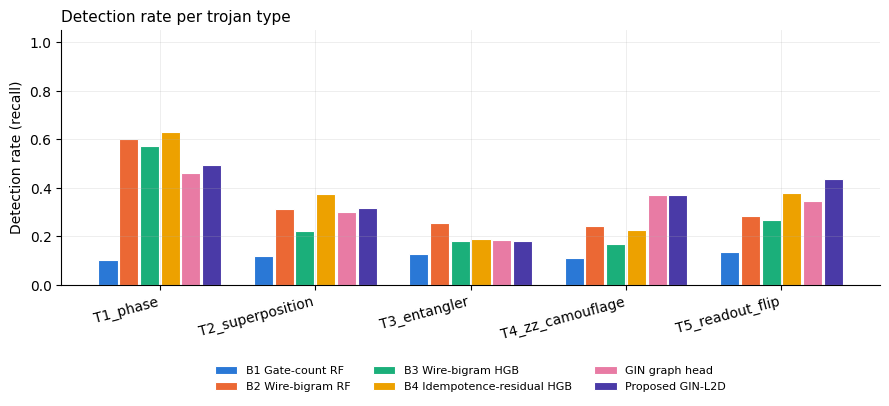

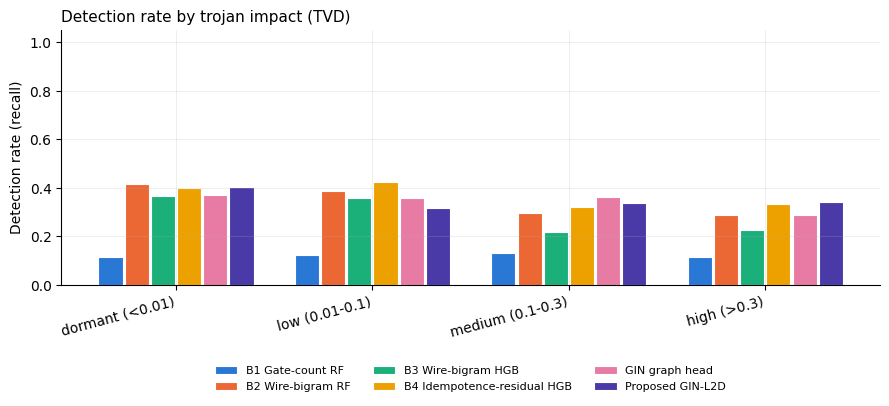

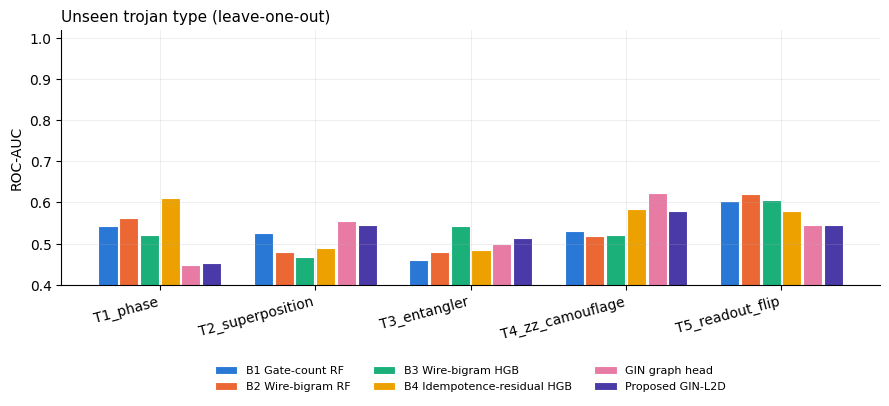

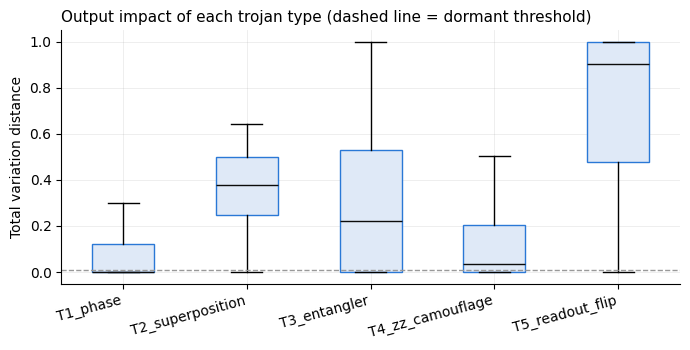

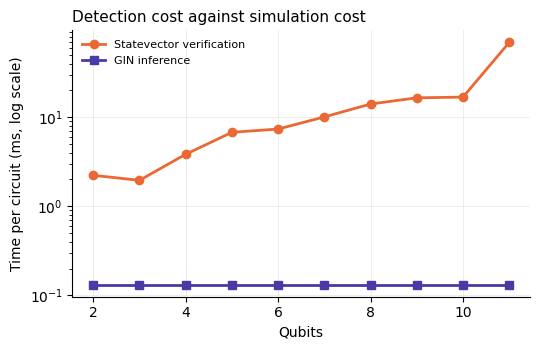

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

MODEL_COLOURS = {"B1 Gate-count RF": "#2a78d6", "B2 Wire-bigram RF": "#eb6834", "B3 Wire-bigram HGB": "#1baf7a",
                 "B4 Idempotence-residual HGB": "#eda100", "GIN graph head": "#e87ba4", "Proposed GIN-L2D": "#4a3aa7",
                 "MGM (self-supervised)": "#008300", "MGM-C (calibrated)": "#1baf7a",
                 "Fusion (GIN-L2D + MGM-C)": "#e34948", "Ensemble (B4 + GIN-L2D + MGM-C)": "#e34948"}
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6, "savefig.dpi": 300})


def grouped_bars(table, ylabel, title, path, ylim=(0, 1.05)):
    fig, ax = plt.subplots(figsize=(9, 4.4))
    n_models = len(table.columns)
    width = 0.8 / n_models
    x = np.arange(len(table.index))
    for k, model_name in enumerate(table.columns):
        ax.bar(x + (k - (n_models - 1) / 2) * width, table[model_name].values, width * 0.92,
               color=MODEL_COLOURS[model_name], label=model_name, edgecolor="white", linewidth=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels([str(i) for i in table.index], rotation=15, ha="right")
    ax.set_ylabel(ylabel)
    ax.set_ylim(*ylim)
    ax.set_title(title, loc="left", fontsize=11)
    ax.legend(frameon=False, ncol=3, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.28))
    fig.tight_layout()
    fig.savefig(path)
    plt.show()


fig, ax = plt.subplots(figsize=(4.8, 4.2))
for model_name in MODEL_ORDER:
    df = e1[e1.model == model_name]
    fpr, tpr, _ = roc_curve(df.label, df.score)
    ax.plot(fpr, tpr, color=MODEL_COLOURS[model_name], linewidth=2,
            label=f"{model_name} (AUC {roc_auc_score(df.label, df.score):.3f})")
ax.plot([0, 1], [0, 1], color="#999999", linewidth=1, linestyle="--")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC, family-held-out CV (pooled folds)", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig("results/fig1_roc.png")
plt.show()

grouped_bars(table4.drop(index="Clean (specificity)"), "Detection rate (recall)",
             "Detection rate per trojan type", "results/fig2_per_trojan_recall.png")
grouped_bars(table5[MODEL_ORDER], "Detection rate (recall)",
             "Detection rate by trojan impact (TVD)", "results/fig3_recall_vs_impact.png")
grouped_bars(table7.drop(index="Mean"), "ROC-AUC", "Unseen trojan type (leave-one-out)",
             "results/fig4_leave_one_out_auc.png", ylim=(0.4, 1.02))

fig, ax = plt.subplots(figsize=(7, 3.6))
data = [meta[meta.kind == k].tvd.values for k in TROJAN_TYPES]
ax.boxplot(data, tick_labels=TROJAN_TYPES, showfliers=False, patch_artist=True,
           boxprops={"facecolor": "#dfe9f7", "edgecolor": "#2a78d6"}, medianprops={"color": "#0b0b0b"})
ax.axhline(0.01, color="#999999", linestyle="--", linewidth=1)
ax.set_ylabel("Total variation distance")
ax.set_title("Output impact of each trojan type (dashed line = dormant threshold)", loc="left", fontsize=11)
plt.setp(ax.get_xticklabels(), rotation=15, ha="right")
fig.tight_layout()
fig.savefig("results/fig5_trojan_impact.png")
plt.show()

fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.plot(table8.index, table8.sim_ms_mean, marker="o", color="#eb6834", linewidth=2, markersize=6,
        label="Statevector verification")
ax.plot(table8.index, table8.gnn_ms_per_circuit, marker="s", color="#4a3aa7", linewidth=2, markersize=6,
        label="GIN inference")
ax.set_yscale("log")
ax.set_xlabel("Qubits")
ax.set_ylabel("Time per circuit (ms, log scale)")
ax.set_title("Detection cost against simulation cost", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig("results/fig6_latency.png")
plt.show()

## 13b. E6 Does evaluation realism explain the gap with prior work?

Prior work reports near-perfect detection with a fixed compiler and a random train/test split. This 2 × 2 experiment separates the two factors:

| | Random split (families shared) | Family-held-out split |
|---|---|---|
| **Fixed compiler** (level 2, all-to-all, no padding) | prior-work setting | |
| **Honest-variation compiler** (sections 2–4) | | realistic setting (E1) |

The same models, epochs and thresholds are used in every cell. At the end, the realistic dataset is restored.

In [ ]:
from sklearn.model_selection import StratifiedKFold


def fixed_compile(qc, rng, basis=("rz", "sx", "x", "cx")):
    compiled = transpile(qc, basis_gates=list(basis), optimization_level=2,
                         seed_transpiler=int(rng.integers(0, 10**6)))
    return compiled, 2, "all_to_all"


def use_dataset(sample_list):
    global samples, meta, graphs, X_counts, X_bigram, X_resid, FEATURE_SETS, y, groups
    samples = sample_list
    meta = pd.DataFrame([{k: v for k, v in s.items() if k not in ("qc", "mask")} for s in samples])
    graphs = [circuit_to_graph(s["qc"], s["mask"], s["label"]) for s in samples]
    X_counts = np.array([gate_count_features(s["qc"]) for s in samples], dtype=float)
    X_bigram = np.array([bigram_features(s["qc"]) for s in samples], dtype=float)
    X_resid = np.array([reoptimisation_residual(s["qc"]) for s in samples], dtype=float)
    for g, r in zip(graphs, X_resid):
        g.r = torch.tensor(np.sign(r) * np.log1p(np.abs(r)), dtype=torch.float32).unsqueeze(0)
    FEATURE_SETS = {"counts": X_counts, "bigram": X_bigram, "bigram+resid": np.hstack([X_bigram, X_resid])}
    y = meta.label.values
    groups = meta.family.values


def run_setting(setting_name, splitter):
    rows = []
    for fold, (train_idx, test_idx) in enumerate(splitter.split(X_counts, y, groups)):
        preds, _, _ = run_models(train_idx, test_idx, fold)
        preds = preds.merge(meta[["label"]].reset_index().rename(columns={"index": "idx"}), on="idx")
        for model_name, df in preds.groupby("model"):
            rows.append({"setting": setting_name, "model": model_name, "fold": fold,
                         "ROC-AUC": roc_auc_score(df.label, df.score),
                         "Recall@val-threshold": float((df[df.label == 1].score >= df.threshold.iloc[0]).mean()),
                         "FPR": float((df[df.label == 0].score >= df.threshold.iloc[0]).mean())})
    print(f"{setting_name}: done")
    return rows


realistic_samples = samples
fixed_samples = build_dataset(base_circuits, compile_fn=fixed_compile, padding_prob=0.0)
random_split = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
family_split = GroupKFold(n_splits=5)

e6_rows = []
use_dataset(fixed_samples)
e6_rows += run_setting("Fixed compiler + random split", random_split)
e6_rows += run_setting("Fixed compiler + family split", family_split)
use_dataset(realistic_samples)
e6_rows += run_setting("Honest variation + random split", random_split)
e6_rows += run_setting("Honest variation + family split", family_split)

e6 = pd.DataFrame(e6_rows)
e6.to_csv("results/e6_realism_full.csv", index=False)
e6_mean = e6.groupby(["setting", "model"])["ROC-AUC"].mean().unstack()[MODEL_ORDER]
e6_std = e6.groupby(["setting", "model"])["ROC-AUC"].std().unstack()[MODEL_ORDER]
SETTING_ORDER = ["Fixed compiler + random split", "Fixed compiler + family split",
                 "Honest variation + random split", "Honest variation + family split"]
table9 = (e6_mean.map("{:.3f}".format) + " ± " + e6_std.map("{:.3f}".format)).reindex(SETTING_ORDER)
table9.to_csv("results/table9_realism_2x2_auc.csv")
table9

  processed 25/220 base circuits, 250 samples
  processed 50/220 base circuits, 500 samples
  processed 75/220 base circuits, 710 samples
  processed 100/220 base circuits, 960 samples
  processed 125/220 base circuits, 1210 samples
  processed 150/220 base circuits, 1410 samples
  processed 175/220 base circuits, 1660 samples
  processed 200/220 base circuits, 1910 samples
Fixed compiler + random split: done
Fixed compiler + family split: done
Honest variation + random split: done
Honest variation + family split: done


model,B1 Gate-count RF,B2 Wire-bigram RF,B3 Wire-bigram HGB,B4 Idempotence-residual HGB,GIN graph head,Proposed GIN-L2D
setting,,,,,,
Fixed compiler + random split,0.876 ± 0.029,0.910 ± 0.025,0.899 ± 0.027,0.922 ± 0.023,0.802 ± 0.034,0.800 ± 0.032
Fixed compiler + family split,0.539 ± 0.036,0.643 ± 0.034,0.655 ± 0.023,0.746 ± 0.046,0.690 ± 0.029,0.693 ± 0.032
Honest variation + random split,0.531 ± 0.024,0.610 ± 0.010,0.645 ± 0.011,0.688 ± 0.017,0.621 ± 0.081,0.711 ± 0.030
Honest variation + family split,0.527 ± 0.019,0.614 ± 0.019,0.610 ± 0.028,0.669 ± 0.024,0.628 ± 0.057,0.683 ± 0.029


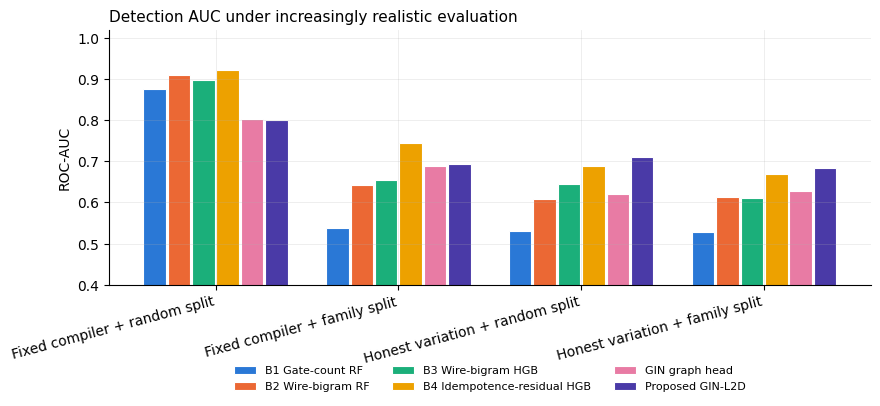

In [ ]:
grouped_bars(e6_mean.reindex(SETTING_ORDER), "ROC-AUC", "Detection AUC under increasingly realistic evaluation",
             "results/fig7_realism_2x2.png", ylim=(0.4, 1.02))

## 13c. E7 Proposed method: self-supervised masked gate modelling (MGM) of honest compiler behaviour

**Idea.** The supervised detectors learn what known trojans look like, so they fail on trojan types they have not seen (Table 7). MGM instead learns what *honest compiler output* looks like and flags gates that do not fit.

**Port graph (removes a shortcut).** In the gate DAG, a masked `cx` would still reveal itself through its two wire connections. MGM therefore uses a *port graph*: every (gate, qubit) incidence is a node, consecutive ports on a wire are linked by wire edges, and the two ports of a `cx` are linked by a gate edge. When a gate is masked, its gate edge is removed, so a masked `cx` looks exactly like two masked single-qubit gates, and the model has to infer from context whether a two-qubit interaction belongs there.

**Training (clean circuits only).** 15% of gates are masked at random, and a GINE network predicts each masked port's class from its context. The 13 classes are: rz in 8 angle bins, sx, x, cx control, cx target and other.

**Scoring.** Gates are split into 8 interleaved groups. Each group is masked in turn, and the surprisal −log p(true class | context) is recorded for every gate. The circuit score is the mean of the three highest gate surprisals, and the gate ranking gives localisation. No trojan example is ever used for training, so every trojan type is unseen by construction.

**Fusion.** MGM is also combined with the supervised GIN-L2D by averaging their within-fold percentile ranks. This uses no labels.

In [ ]:
from torch_geometric.nn import GINEConv

MGM_ANGLE_BINS = 8
MGM_CLASSES = MGM_ANGLE_BINS + 5


def port_class(name, theta, port, angle_bins=MGM_ANGLE_BINS):
    if name == "rz":
        return int((theta % (2 * np.pi)) / (2 * np.pi) * angle_bins) % angle_bins
    if name == "sx":
        return angle_bins
    if name == "x":
        return angle_bins + 1
    if name == "cx":
        return angle_bins + 2 + min(port, 1)
    return angle_bins + 4


def circuit_to_port_graph(qc, label=0):
    n_qubits = qc.num_qubits
    qubit_lists = [[qc.find_bit(q).index for q in inst.qubits] for inst in qc.data]
    wire_len = np.zeros(n_qubits)
    for qidx in qubit_lists:
        wire_len[qidx] += 1
    feats, classes, port_gate = [], [], []
    wire_src, wire_dst, gate_src, gate_dst = [], [], [], []
    last_port, wire_count = {}, np.zeros(n_qubits)
    for i, (inst, qidx) in enumerate(zip(qc.data, qubit_lists)):
        name, theta = inst.operation.name, gate_angle(inst.operation)
        ports = []
        for k, q in enumerate(qidx):
            p = len(classes)
            c = port_class(name, theta, k)
            wire_count[q] += 1
            onehot = np.zeros(MGM_CLASSES)
            onehot[c] = 1.0
            is_rz = name == "rz"
            feats.append(list(onehot) + [np.sin(theta) if is_rz else 0.0, np.cos(theta) if is_rz else 0.0,
                                         wire_count[q] / max(wire_len[q], 1), q / max(n_qubits - 1, 1),
                                         float(q not in last_port), 0.0, n_qubits / 12.0, 0.0])
            classes.append(c)
            port_gate.append(i)
            if q in last_port:
                wire_src.append(last_port[q])
                wire_dst.append(p)
            last_port[q] = p
            ports.append(p)
        for a in ports:
            for b in ports:
                if a != b:
                    gate_src.append(a)
                    gate_dst.append(b)
    x = np.array(feats, dtype=np.float32)
    x[list(last_port.values()), MGM_CLASSES + 5] = 1.0
    wire_edges = np.array([wire_src + wire_dst, wire_dst + wire_src], dtype=np.int64).reshape(2, -1)
    gate_edges = np.array([gate_src, gate_dst], dtype=np.int64).reshape(2, -1)
    return Data(x_base=torch.tensor(x), num_nodes=len(classes), y_port=torch.tensor(classes, dtype=torch.long),
                port_gate=torch.tensor(port_gate, dtype=torch.long), n_gates=torch.tensor([qc.size()]),
                wire_edge_index=torch.tensor(wire_edges), gate_edge_index=torch.tensor(gate_edges),
                y=torch.tensor([float(label)]))


def batch_gate_keys(batch):
    offsets = torch.cumsum(batch.n_gates, 0) - batch.n_gates
    return batch.port_gate + offsets[batch.batch]


def masked_inputs(batch, masked_port):
    x = batch.x_base.clone()
    x[masked_port, :MGM_CLASSES + 2] = 0.0
    x[:, -1] = masked_port.float()
    keep = ~masked_port[batch.gate_edge_index[0]]
    gate_edges = batch.gate_edge_index[:, keep]
    edge_index = torch.cat([batch.wire_edge_index, gate_edges], dim=1)
    edge_attr = torch.cat([torch.tensor([[1.0, 0.0]], device=x.device).repeat(batch.wire_edge_index.shape[1], 1),
                           torch.tensor([[0.0, 1.0]], device=x.device).repeat(gate_edges.shape[1], 1)], dim=0)
    return x, edge_index, edge_attr


def build_mgm(in_dim, n_classes=MGM_CLASSES, hidden=96, layers=4, dropout=0.1):
    convs, norms = nn.ModuleList(), nn.ModuleList()
    for layer in range(layers):
        d = in_dim if layer == 0 else hidden
        mlp = nn.Sequential(nn.Linear(d, hidden), nn.ReLU(), nn.Linear(hidden, hidden))
        convs.append(GINEConv(mlp, edge_dim=2, train_eps=True))
        norms.append(nn.BatchNorm1d(hidden))
    return nn.ModuleDict({"convs": convs, "norms": norms, "dropout": nn.Dropout(dropout),
                          "head": nn.Sequential(nn.Linear(hidden * layers, hidden), nn.ReLU(),
                                                nn.Linear(hidden, n_classes))})


def mgm_forward(model, x, edge_index, edge_attr):
    h, outputs = x, []
    for conv, norm in zip(model["convs"], model["norms"]):
        h = model["dropout"](F.relu(norm(conv(h, edge_index, edge_attr))))
        outputs.append(h)
    return model["head"](torch.cat(outputs, dim=1))


def mgm_loss(model, batch, mask_prob=0.15, generator=None):
    keys = batch_gate_keys(batch)
    gate_masked = torch.rand(int(batch.n_gates.sum()), device=keys.device, generator=generator) < mask_prob
    masked_port = gate_masked[keys]
    if not masked_port.any():
        masked_port[0] = True
    x, edge_index, edge_attr = masked_inputs(batch, masked_port)
    logits = mgm_forward(model, x, edge_index, edge_attr)
    return F.cross_entropy(logits[masked_port], batch.y_port[masked_port])


def train_mgm(train_graphs, val_graphs, epochs=30, lr=1e-3, batch_size=32, mask_prob=0.15, layers=4, seed=42):
    set_seed(seed)
    model = build_mgm(train_graphs[0].x_base.shape[1], layers=layers).to(DEVICE)
    optimiser = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimiser, T_max=epochs)
    loader = DataLoader(train_graphs, batch_size=batch_size, shuffle=True)
    best_loss, best_state = np.inf, None
    for epoch in range(epochs):
        model.train()
        for batch in loader:
            batch = batch.to(DEVICE)
            optimiser.zero_grad()
            loss = mgm_loss(model, batch, mask_prob)
            loss.backward()
            optimiser.step()
        scheduler.step()
        model.eval()
        generator = torch.Generator(device=DEVICE)
        generator.manual_seed(0)
        with torch.no_grad():
            val_loss = np.mean([mgm_loss(model, b.to(DEVICE), mask_prob, generator).item()
                                for b in DataLoader(val_graphs, batch_size=batch_size)])
        if val_loss < best_loss:
            best_loss, best_state = val_loss, {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, best_loss


def mgm_gate_surprisal(model, graph_list, n_groups=8, batch_size=32):
    """Per-gate surprisal for every circuit, each gate scored while masked."""
    model.eval()
    results = []
    with torch.no_grad():
        for batch in DataLoader(graph_list, batch_size=batch_size):
            batch = batch.to(DEVICE)
            keys = batch_gate_keys(batch)
            port_surprisal = torch.zeros(batch.num_nodes, device=DEVICE)
            for k in range(n_groups):
                masked_port = (batch.port_gate % n_groups) == k
                if not masked_port.any():
                    continue
                x, edge_index, edge_attr = masked_inputs(batch, masked_port)
                log_probs = F.log_softmax(mgm_forward(model, x, edge_index, edge_attr), dim=1)
                surprisal = -log_probs.gather(1, batch.y_port.unsqueeze(1)).squeeze(1)
                port_surprisal[masked_port] = surprisal[masked_port]
            total = int(batch.n_gates.sum())
            gate_sum = torch.zeros(total, device=DEVICE).index_add_(0, keys, port_surprisal)
            gate_count = torch.zeros(total, device=DEVICE).index_add_(0, keys, torch.ones_like(port_surprisal))
            gate_scores = (gate_sum / gate_count.clamp(min=1)).cpu().numpy()
            results.extend(np.split(gate_scores, np.cumsum(batch.n_gates.cpu().numpy())[:-1]))
    return results


def mgm_circuit_score(gate_surprisal, top_k=3):
    return float(np.sort(gate_surprisal)[-top_k:].mean())


def gate_names(qc):
    return [inst.operation.name for inst in qc.data]


def fit_surprisal_reference(gate_scores_list, names_list):
    pooled = {}
    for scores, names in zip(gate_scores_list, names_list):
        for s, name in zip(scores, names):
            pooled.setdefault(name, []).append(s)
    reference = {name: np.sort(values) for name, values in pooled.items()}
    reference["__all__"] = np.sort(np.concatenate(list(reference.values())))
    return reference


def calibrated_gate_scores(scores, names, reference):
    """-log10 empirical p-value of each gate's surprisal against honest gates of the same type."""
    scores, names = np.asarray(scores), np.asarray(names)
    out = np.empty(len(scores))
    for name in np.unique(names):
        ref = reference.get(name, reference["__all__"])
        sel = names == name
        exceed = len(ref) - np.searchsorted(ref, scores[sel], side="left")
        out[sel] = -np.log10((1 + exceed) / (1 + len(ref)))
    return out


def calibrated_circuit_score(calibrated_scores):
    """Bonferroni-style size correction: -log10(min p-value x number of gates)."""
    return float(calibrated_scores.max() - np.log10(len(calibrated_scores)))


def mgm_calibration(model, clean_idx, fpr=0.10):
    """Reference from one half of the clean validation circuits, thresholds from the other half."""
    half_a, half_b = clean_idx[0::2], clean_idx[1::2]
    reference = fit_surprisal_reference(mgm_gate_surprisal(model, [port_graphs[i] for i in half_a]),
                                        [gate_names(samples[i]["qc"]) for i in half_a])
    b_scores = mgm_gate_surprisal(model, [port_graphs[i] for i in half_b])
    raw_b = np.array([mgm_circuit_score(s) for s in b_scores])
    cal_b = np.array([calibrated_circuit_score(calibrated_gate_scores(s, gate_names(samples[i]["qc"]), reference))
                      for s, i in zip(b_scores, half_b)])
    return {"reference": reference, "raw_threshold": float(np.quantile(raw_b, 1 - fpr)),
            "cal_threshold": float(np.quantile(cal_b, 1 - fpr)), "raw_clean": np.sort(raw_b), "cal_clean": np.sort(cal_b)}


def clean_only(idx):
    return idx[meta.label.values[idx] == 0]


t0 = time.time()
port_graphs = [circuit_to_port_graph(s["qc"], s["label"]) for s in samples]
print(f"{len(port_graphs)} port graphs built in {time.time() - t0:.0f} s")

2086 port graphs built in 7 s


### E7-1 Family-held-out 5-fold CV (same folds as E1)

For each fold, MGM is trained on the clean circuits of the training families. The clean circuits of the validation families are split in two halves:
* **Half A** gives the honest surprisal distribution for each gate type.
* **Half B** gives the thresholds at a 10% false-positive rate.

Two circuit scores are reported:
* **MGM (raw)**: the mean of the three highest raw gate surprisals
* **MGM-C (calibrated)**: each gate's surprisal is converted into an empirical p-value against honest gates of the same type, and the circuit score is −log10(min p × number of gates). This corrects the two problems found in v4: honest rz gates are naturally uncertain, and large circuits contain more chance outliers.

In [ ]:
e7_rows, e7_gate_scores, e7_cal_gate_scores = [], {}, {}
for fold, (train_idx, test_idx) in enumerate(GroupKFold(n_splits=5).split(X_counts, y, groups)):
    t0 = time.time()
    tr, va = split_validation(train_idx, seed=fold)
    mgm, val_loss = train_mgm([port_graphs[i] for i in clean_only(tr)], [port_graphs[i] for i in clean_only(va)])
    calib = mgm_calibration(mgm, clean_only(va))
    for i, s in zip(test_idx, mgm_gate_surprisal(mgm, [port_graphs[i] for i in test_idx])):
        cal = calibrated_gate_scores(s, gate_names(samples[i]["qc"]), calib["reference"])
        e7_gate_scores[i], e7_cal_gate_scores[i] = s, cal
        e7_rows.append({"fold": fold, "idx": i, "MGM (self-supervised)": mgm_circuit_score(s),
                        "MGM-C (calibrated)": calibrated_circuit_score(cal),
                        "threshold_raw": calib["raw_threshold"], "threshold_cal": calib["cal_threshold"]})
    print(f"fold {fold}: MGM val masked-gate loss = {val_loss:.3f}, {time.time() - t0:.0f} s")

e7 = pd.DataFrame(e7_rows).merge(meta.reset_index().rename(columns={"index": "idx"}), on="idx")
e1_wide = e1.pivot_table(index="idx", columns="model", values="score")[["B4 Idempotence-residual HGB", "Proposed GIN-L2D"]]
e7 = e7.merge(e1_wide.reset_index(), on="idx")
e7["Fusion (GIN-L2D + MGM-C)"] = 0.5 * (e7.groupby("fold")["Proposed GIN-L2D"].rank(pct=True) +
                                        e7.groupby("fold")["MGM-C (calibrated)"].rank(pct=True))
e7.to_csv("results/e7_mgm_predictions.csv", index=False)

E7_MODELS = ["B4 Idempotence-residual HGB", "Proposed GIN-L2D", "MGM (self-supervised)", "MGM-C (calibrated)",
             "Fusion (GIN-L2D + MGM-C)"]


def per_type_auc(df, score_col):
    out = {kind: roc_auc_score(df[(df.kind == kind) | (df.label == 0)].label,
                               df[(df.kind == kind) | (df.label == 0)][score_col]) for kind in TROJAN_TYPES}
    out["All"] = roc_auc_score(df.label, df[score_col])
    return out


table10 = pd.DataFrame({m: per_type_auc(e7, m) for m in E7_MODELS}).round(3)
fold_auc = pd.DataFrame({m: e7.groupby("fold").apply(lambda d: roc_auc_score(d.label, d[m])) for m in E7_MODELS})
table10.loc["All (mean ± std over folds)"] = [f"{fold_auc[m].mean():.3f} ± {fold_auc[m].std():.3f}" for m in E7_MODELS]
table10.to_csv("results/table10_mgm_auc_by_type.csv")
table10

fold 0: MGM val masked-gate loss = 1.279, 12 s
fold 1: MGM val masked-gate loss = 0.979, 11 s
fold 2: MGM val masked-gate loss = 1.340, 10 s
fold 3: MGM val masked-gate loss = 1.093, 11 s
fold 4: MGM val masked-gate loss = 1.084, 11 s


,B4 Idempotence-residual HGB,Proposed GIN-L2D,MGM (self-supervised),MGM-C (calibrated),Fusion (GIN-L2D + MGM-C)
T1_phase,0.823,0.712,0.742,0.73,0.758
T2_superposition,0.686,0.617,0.596,0.697,0.715
T3_entangler,0.558,0.552,0.505,0.546,0.579
T4_zz_camouflage,0.603,0.695,0.517,0.546,0.676
T5_readout_flip,0.668,0.76,0.526,0.563,0.736
All,0.668,0.667,0.577,0.616,0.693
All (mean ± std over folds),0.669 ± 0.024,0.689 ± 0.028,0.581 ± 0.029,0.621 ± 0.037,0.693 ± 0.017


In [ ]:
def recall_by_kind(df, score_col, threshold_col):
    flagged = df[score_col] >= df[threshold_col]
    out = flagged[df.label == 1].groupby(df.kind[df.label == 1]).mean()
    out.loc["Clean (false-positive rate)"] = flagged[df.label == 0].mean()
    return out


def localisation_table(gate_scores):
    loc = localisation_metrics([i for i in gate_scores if samples[i]["label"] == 1], gate_scores)
    table = loc.groupby("kind").mean(numeric_only=True).drop(columns="gates")
    table.loc["All"] = loc.mean(numeric_only=True).drop("gates")
    return table


loc_raw, loc_cal = localisation_table(e7_gate_scores), localisation_table(e7_cal_gate_scores)
table11 = pd.DataFrame({
    "MGM recall @ val threshold": recall_by_kind(e7, "MGM (self-supervised)", "threshold_raw"),
    "MGM-C recall @ val threshold": recall_by_kind(e7, "MGM-C (calibrated)", "threshold_cal"),
    "MGM Hit@1": loc_raw["Hit@1"], "MGM-C Hit@1": loc_cal["Hit@1"],
    "MGM Hit@5": loc_raw["Hit@5"], "MGM-C Hit@5": loc_cal["Hit@5"],
    "Random@1": loc_raw["Random@1"], "Random@5": loc_raw["Random@5"]}).round(3)
table11.to_csv("results/table11_mgm_recall_localisation.csv")
table11

,MGM recall @ val threshold,MGM-C recall @ val threshold,MGM Hit@1,MGM-C Hit@1,MGM Hit@5,MGM-C Hit@5,Random@1,Random@5
kind,,,,,,,,
All,NaN,NaN,0.246,0.262,0.470,0.530,0.023,0.107
Clean (false-positive rate),0.074,0.178,NaN,NaN,NaN,NaN,NaN,NaN
T1_phase,0.332,0.500,0.538,0.413,0.774,0.678,0.016,0.082
T2_superposition,0.101,0.394,0.365,0.471,0.582,0.716,0.018,0.091
T3_entangler,0.077,0.226,0.058,0.139,0.202,0.428,0.016,0.079
T4_zz_camouflage,0.057,0.186,0.114,0.090,0.367,0.310,0.047,0.200
T5_readout_flip,0.072,0.201,0.158,0.196,0.426,0.522,0.017,0.084


### E7-2 Direct comparison with supervised models on unseen trojan types

The comparison uses the same outer family split as E2 (Table 7). The supervised models never saw the held-out trojan type, while MGM and MGM-C never saw any trojan at all.

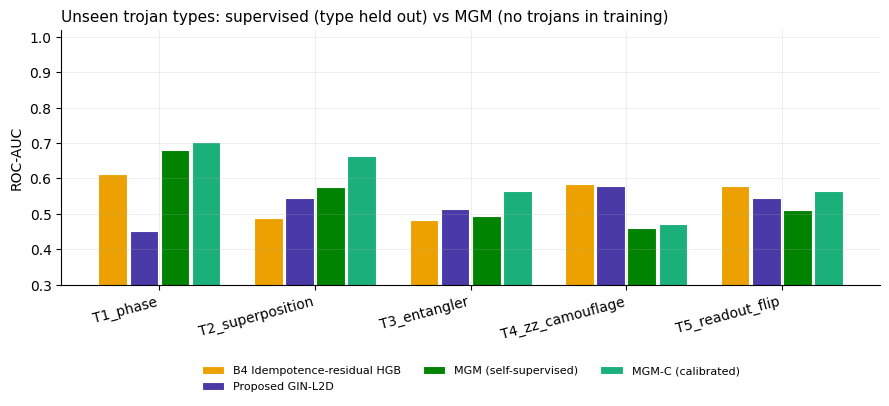

model,B4 Idempotence-residual HGB,Proposed GIN-L2D,MGM (self-supervised),MGM-C (calibrated)
held_out,,,,
T1_phase,0.612,0.453,0.681,0.703
T2_superposition,0.488,0.544,0.576,0.663
T3_entangler,0.484,0.513,0.494,0.564
T4_zz_camouflage,0.585,0.580,0.459,0.471
T5_readout_flip,0.580,0.546,0.510,0.566
Mean,0.550,0.527,0.544,0.593


In [ ]:
tr_outer, va_outer = split_validation(train_all, seed=0)
mgm_outer, _ = train_mgm([port_graphs[i] for i in clean_only(tr_outer)], [port_graphs[i] for i in clean_only(va_outer)])
calib_outer = mgm_calibration(mgm_outer, clean_only(va_outer))
outer_gate_scores = mgm_gate_surprisal(mgm_outer, [port_graphs[i] for i in test_all])
outer_df = meta.iloc[test_all].assign(**{
    "MGM (self-supervised)": [mgm_circuit_score(s) for s in outer_gate_scores],
    "MGM-C (calibrated)": [calibrated_circuit_score(calibrated_gate_scores(s, gate_names(samples[i]["qc"]),
                                                                           calib_outer["reference"]))
                           for s, i in zip(outer_gate_scores, test_all)]})
table12 = table7.drop(index="Mean")[["B4 Idempotence-residual HGB", "Proposed GIN-L2D"]].copy()
for col in ["MGM (self-supervised)", "MGM-C (calibrated)"]:
    unseen = per_type_auc(outer_df, col)
    table12[col] = [unseen[k] for k in table12.index]
table12.loc["Mean"] = table12.mean()
table12 = table12.round(3)
table12.to_csv("results/table12_unseen_trojan_auc.csv")
grouped_bars(table12.drop(index="Mean"), "ROC-AUC",
             "Unseen trojan types: supervised (type held out) vs MGM (no trojans in training)",
             "results/fig8_unseen_trojans.png", ylim=(0.3, 1.02))
table12

### E7-3 Gate-level evidence: inserted gates are anomalous, but raw scores mix gate types

For every trojaned test circuit in E7-1, inserted gates are compared with honest gates of the same type in the same circuits. The last two rows pool all gate types: once with raw surprisal, and once with type-calibrated scores. If pooled raw AUC is clearly below the per-type AUCs while the calibrated pooled AUC recovers, that confirms raw circuit scores are drowned out by naturally uncertain honest gates.

In [ ]:
def gate_surprisal_table(raw_scores, cal_scores):
    rows = []
    for i, raw in raw_scores.items():
        if samples[i]["label"] == 0:
            continue
        for name, is_trojan, r, c in zip(gate_names(samples[i]["qc"]), samples[i]["mask"], raw, cal_scores[i]):
            rows.append({"gate": name, "trojan": bool(is_trojan), "raw": float(r), "calibrated": float(c)})
    return pd.DataFrame(rows)


gate_df = gate_surprisal_table(e7_gate_scores, e7_cal_gate_scores)
table15_rows = []
for gate in GATE_VOCAB:
    d = gate_df[gate_df.gate == gate]
    if d.trojan.nunique() < 2:
        continue
    table15_rows.append({"gate": gate, "honest_gates": int((~d.trojan).sum()), "trojan_gates": int(d.trojan.sum()),
                         "honest_mean_surprisal": d[~d.trojan].raw.mean(), "trojan_mean_surprisal": d[d.trojan].raw.mean(),
                         "AUC_trojan_vs_honest": roc_auc_score(d.trojan, d.raw)})
for col, label in [("raw", "all gate types, raw surprisal"), ("calibrated", "all gate types, calibrated")]:
    table15_rows.append({"gate": label, "honest_gates": int((~gate_df.trojan).sum()),
                         "trojan_gates": int(gate_df.trojan.sum()),
                         "AUC_trojan_vs_honest": roc_auc_score(gate_df.trojan, gate_df[col])})
table15 = pd.DataFrame(table15_rows).set_index("gate").round(3)
table15.to_csv("results/table15_gate_surprisal.csv")
table15

,honest_gates,trojan_gates,honest_mean_surprisal,trojan_mean_surprisal,AUC_trojan_vs_honest
gate,,,,,
rz,77799,418,1.636,4.398,0.822
sx,34782,208,0.399,4.085,0.955
x,16138,209,0.764,3.047,0.889
cx,57843,628,0.652,1.383,0.770
"all gate types, raw surprisal",186562,1463,NaN,NaN,0.786
"all gate types, calibrated",186562,1463,NaN,NaN,0.826


## 13d. E8 Adaptive attacker with an attack budget, and an ensemble defence

* **Splits.** Two family splits are used: the outer split of E2 (split A) and a second family split (split B).
* **Detectors.** For each split:
  * B4 and GIN-L2D are trained on all five trojan types using the training families.
  * MGM is trained on clean circuits only.
  * MGM-C is calibrated on half A of the clean validation circuits.
  * The **ensemble** averages the empirical-CDF positions of the B4, GIN-L2D and MGM-C scores, each measured against that detector's own scores on half B of the clean validation circuits.
  * Thresholds are set at a 10% false-positive rate on validation circuits.
* **Attack.** For every test base circuit and trojan type, the attacker compiles honestly, draws 32 candidate insertions and keeps those with TVD ≥ 0.05. With a budget of k, the attacker sees the first k feasible candidates:
  * **Random placement**: the first feasible candidate
  * **Adaptive placement against detector D**: the candidate with the lowest score under D (white-box). To evade the ensemble, the attacker must keep all three member scores low at once.
* **Main metric.** ROC-AUC of the attacked trojans against the clean test circuits of the same split (threshold-free). All clean and candidate scores are saved.

In [ ]:
ATTACK_BUDGETS = (1, 2, 4, 8, 16, 32)
ENSEMBLE = "Ensemble (B4 + GIN-L2D + MGM-C)"
ENSEMBLE_MEMBERS = ["B4 Idempotence-residual HGB", "Proposed GIN-L2D", "MGM-C (calibrated)"]
DETECTOR_NAMES = ["B4 Idempotence-residual HGB", "Proposed GIN-L2D", "MGM (self-supervised)", "MGM-C (calibrated)", ENSEMBLE]


def graph_with_residual(qc):
    graph = circuit_to_graph(qc)
    r = np.array(reoptimisation_residual(qc), dtype=float)
    graph.r = torch.tensor(np.sign(r) * np.log1p(np.abs(r)), dtype=torch.float32).unsqueeze(0)
    return graph


def ecdf(sorted_reference, values):
    return np.searchsorted(sorted_reference, values, side="right") / max(len(sorted_reference), 1)


def score_all(det, circuits):
    """Scores of every detector for a list of circuits (MGM surprisal is computed once)."""
    X = np.array([bigram_features(qc) + reoptimisation_residual(qc) for qc in circuits], dtype=float)
    gate_s = mgm_gate_surprisal(det["mgm"], [circuit_to_port_graph(qc) for qc in circuits])
    scores = {
        "B4 Idempotence-residual HGB": det["b4"].predict_proba(X)[:, 1],
        "Proposed GIN-L2D": predict_gnn(det["gin"], [graph_with_residual(qc) for qc in circuits])[1],
        "MGM (self-supervised)": np.array([mgm_circuit_score(s) for s in gate_s]),
        "MGM-C (calibrated)": np.array([calibrated_circuit_score(calibrated_gate_scores(s, gate_names(qc), det["reference"]))
                                        for s, qc in zip(gate_s, circuits)]),
    }
    if "clean_reference" in det:
        scores[ENSEMBLE] = np.mean([ecdf(det["clean_reference"][n], scores[n]) for n in ENSEMBLE_MEMBERS], axis=0)
    return scores


def prepare_detectors(train_idx, seed=0, fpr=0.10):
    tr, va = split_validation(train_idx, seed=seed)
    X_b4 = FEATURE_SETS["bigram+resid"]
    det = {"b4": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=42).fit(X_b4[tr], y[tr])}
    det["gin"], _ = train_gnn([graphs[i] for i in tr], [graphs[i] for i in va])
    det["mgm"], _ = train_mgm([port_graphs[i] for i in clean_only(tr)], [port_graphs[i] for i in clean_only(va)])
    calib = mgm_calibration(det["mgm"], clean_only(va))
    det["reference"] = calib["reference"]
    half_b = clean_only(va)[1::2]
    half_b_scores = score_all(det, [samples[i]["qc"] for i in half_b])
    det["clean_reference"] = {n: np.sort(half_b_scores[n]) for n in ENSEMBLE_MEMBERS}
    ensemble_clean = np.mean([ecdf(det["clean_reference"][n], half_b_scores[n]) for n in ENSEMBLE_MEMBERS], axis=0)
    det["thresholds"] = {
        "B4 Idempotence-residual HGB": threshold_at_fpr(y[va], det["b4"].predict_proba(X_b4[va])[:, 1], fpr),
        "Proposed GIN-L2D": threshold_at_fpr(y[va], predict_gnn(det["gin"], [graphs[i] for i in va])[1], fpr),
        "MGM (self-supervised)": calib["raw_threshold"],
        "MGM-C (calibrated)": calib["cal_threshold"],
        ENSEMBLE: float(np.quantile(ensemble_clean, 1 - fpr)),
    }
    return det


def attack_candidates(base_qc, kind, rng, n_candidates=32, min_tvd=0.05, max_gates=1500):
    compiled, _, _ = honest_compile(base_qc, rng)
    compiled, _ = dd_padding(compiled, rng)
    if compiled.size() + 3 > max_gates:
        return []
    p_clean = output_probabilities(compiled)
    feasible = []
    for _ in range(n_candidates):
        qc, _ = insert_trojan(compiled, kind, rng)
        tvd, _ = impact(p_clean, output_probabilities(qc))
        if tvd >= min_tvd:
            feasible.append((qc, tvd))
    return feasible


def run_attack(det, test_base_ids, split, n_candidates=32, seed=123):
    rng = np.random.default_rng(seed)
    records = []
    for count, b in enumerate(test_base_ids):
        for kind in TROJAN_TYPES:
            feasible = attack_candidates(base_circuits[b]["qc"], kind, rng, n_candidates=n_candidates)
            if not feasible:
                continue
            record = {"split": split, "base_id": b, "kind": kind, "tvd": np.array([t for _, t in feasible])}
            record.update(score_all(det, [qc for qc, _ in feasible]))
            records.append(record)
        if (count + 1) % 10 == 0:
            print(f"  {split}: attacked {count + 1}/{len(test_base_ids)} base circuits")
    return records


def chosen_index(record, attacker, budget):
    if attacker == "Random placement":
        return 0
    k = min(budget, len(record["tvd"]))
    return int(np.argmin(record[attacker][:k]))


def attack_metrics(records, clean_scores, thresholds, attacker, budget):
    rows = []
    for split in sorted({r["split"] for r in records}):
        split_records = [r for r in records if r["split"] == split]
        for name in DETECTOR_NAMES:
            trojan_scores = np.array([r[name][chosen_index(r, attacker, budget)] for r in split_records])
            clean = clean_scores[split][name]
            labels = np.r_[np.ones(len(trojan_scores)), np.zeros(len(clean))]
            rows.append({"split": split, "attacker": attacker, "budget": budget, "detector": name,
                         "n_attacked": len(trojan_scores), "n_clean": len(clean),
                         "AUC": roc_auc_score(labels, np.r_[trojan_scores, clean]),
                         "detection": float((trojan_scores >= thresholds[split][name]).mean()),
                         "FPR": float((clean >= thresholds[split][name]).mean())})
    return rows


attack_splits = {
    "split A": (train_all, test_all),
    "split B": next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=11).split(X_counts, y, groups)),
}
attack_records, clean_scores, thresholds, clean_rows = [], {}, {}, []
for split, (train_idx, test_idx) in attack_splits.items():
    t0 = time.time()
    det = prepare_detectors(train_idx)
    thresholds[split] = det["thresholds"]
    clean_idx = clean_only(test_idx)
    clean_scores[split] = score_all(det, [samples[i]["qc"] for i in clean_idx])
    clean_rows += [{"split": split, "idx": i, **{n: clean_scores[split][n][j] for n in DETECTOR_NAMES}}
                   for j, i in enumerate(clean_idx)]
    attack_records += run_attack(det, sorted(set(meta.base_id.values[test_idx])), split)
    print(f"{split}: test families = {sorted(set(groups[test_idx]))}, {time.time() - t0:.0f} s")

pd.DataFrame(clean_rows).to_csv("results/e8_clean_test_scores.csv", index=False)
pd.DataFrame([{"split": r["split"], "base_id": r["base_id"], "kind": r["kind"], "candidate": j, "tvd": r["tvd"][j],
               **{name: r[name][j] for name in DETECTOR_NAMES}}
              for r in attack_records for j in range(len(r["tvd"]))]).to_csv("results/e8_attack_candidates.csv", index=False)
pd.DataFrame(thresholds).to_csv("results/e8_thresholds.csv")

attack_eval = pd.DataFrame([row for attacker in ["Random placement"] + DETECTOR_NAMES for budget in ATTACK_BUDGETS
                            for row in attack_metrics(attack_records, clean_scores, thresholds, attacker, budget)])
attack_eval.to_csv("results/e8_attack_metrics.csv", index=False)
print(f"{len(attack_records)} attacked (circuit, trojan) pairs across {len(attack_splits)} splits")

  split A: attacked 10/30 base circuits
  split A: attacked 20/30 base circuits
  split A: attacked 30/30 base circuits
split A: test families = ['ae', 'basis_change', 'bmw_quark_copula', 'error_correctiond3', 'grover', 'qaoa', 'qec_en'], 228 s
  split B: attacked 10/47 base circuits
  split B: attacked 20/47 base circuits
  split B: attacked 30/47 base circuits
  split B: attacked 40/47 base circuits
split B: test families = ['basis_trotter', 'bv', 'error_correctiond3', 'ghz', 'hhl', 'qft', 'teleportation'], 214 s
342 attacked (circuit, trojan) pairs across 2 splits


In [ ]:
table13 = (attack_eval[attack_eval.budget == max(ATTACK_BUDGETS)]
           .pivot_table(index="attacker", columns="detector", values="AUC")
           .reindex(["Random placement"] + DETECTOR_NAMES)[DETECTOR_NAMES])
table13.index = ["Random placement"] + [f"Adaptive vs {n}" for n in DETECTOR_NAMES]
table13 = table13.round(3)
table13.to_csv("results/table13_attack_transfer_auc.csv")
table13

detector,B4 Idempotence-residual HGB,Proposed GIN-L2D,MGM (self-supervised),MGM-C (calibrated),Ensemble (B4 + GIN-L2D + MGM-C)
Random placement,0.658,0.623,0.585,0.626,0.697
Adaptive vs B4 Idempotence-residual HGB,0.486,0.599,0.562,0.593,0.588
Adaptive vs Proposed GIN-L2D,0.607,0.484,0.549,0.567,0.581
Adaptive vs MGM (self-supervised),0.625,0.588,0.488,0.488,0.609
Adaptive vs MGM-C (calibrated),0.634,0.592,0.513,0.460,0.598
Adaptive vs Ensemble (B4 + GIN-L2D + MGM-C),0.524,0.512,0.523,0.490,0.513


In [ ]:
summary_rows = []
for name in DETECTOR_NAMES:
    rnd = attack_eval[(attack_eval.attacker == "Random placement") & (attack_eval.detector == name) &
                      (attack_eval.budget == 1)]
    adv = attack_eval[(attack_eval.attacker == name) & (attack_eval.detector == name) &
                      (attack_eval.budget == max(ATTACK_BUDGETS))]
    summary_rows.append({"detector": name,
                         "AUC random": rnd.AUC.mean(), "AUC white-box (budget 32)": adv.AUC.mean(),
                         "detection random": rnd.detection.mean(), "detection white-box": adv.detection.mean(),
                         "FPR on clean test": rnd.FPR.mean()})
table14 = pd.DataFrame(summary_rows).set_index("detector").round(3)
table14.to_csv("results/table14_white_box_attack_summary.csv")
table14

,AUC random,AUC white-box (budget 32),detection random,detection white-box,FPR on clean test
detector,,,,,
B4 Idempotence-residual HGB,0.658,0.486,0.306,0.082,0.077
Proposed GIN-L2D,0.623,0.484,0.444,0.248,0.266
MGM (self-supervised),0.585,0.488,0.397,0.303,0.304
MGM-C (calibrated),0.626,0.460,0.522,0.272,0.333
Ensemble (B4 + GIN-L2D + MGM-C),0.697,0.513,0.577,0.348,0.350


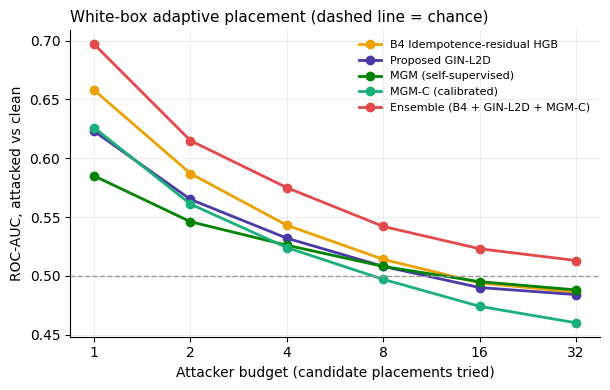

detector,B4 Idempotence-residual HGB,Proposed GIN-L2D,MGM (self-supervised),MGM-C (calibrated),Ensemble (B4 + GIN-L2D + MGM-C)
budget,,,,,
1,0.658,0.623,0.585,0.626,0.697
2,0.587,0.565,0.546,0.561,0.615
4,0.543,0.532,0.526,0.524,0.575
8,0.514,0.508,0.508,0.497,0.542
16,0.494,0.490,0.495,0.474,0.523
32,0.486,0.484,0.488,0.460,0.513


In [ ]:
table16 = (attack_eval[attack_eval.attacker == attack_eval.detector]
           .pivot_table(index="budget", columns="detector", values="AUC")[DETECTOR_NAMES].round(3))
table16.to_csv("results/table16_attack_budget_curve.csv")

fig, ax = plt.subplots(figsize=(6.2, 4.0))
for name in DETECTOR_NAMES:
    ax.plot(table16.index, table16[name], marker="o", linewidth=2, markersize=6,
            color=MODEL_COLOURS[name], label=name)
ax.axhline(0.5, color="#999999", linestyle="--", linewidth=1)
ax.set_xscale("log", base=2)
ax.set_xticks(list(ATTACK_BUDGETS))
ax.set_xticklabels([str(b) for b in ATTACK_BUDGETS])
ax.set_xlabel("Attacker budget (candidate placements tried)")
ax.set_ylabel("ROC-AUC, attacked vs clean")
ax.set_title("White-box adaptive placement (dashed line = chance)", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig("results/fig9_attack_budget.png")
plt.show()
table16

## 15. Revision experiments (reviewer comments)

This section answers the reviewer's requests. Every experiment reuses the dataset, features and model code from sections 1–13, so all earlier numbers stay comparable.

| Code | Experiment | Reviewer point |
|---|---|---|
| R1 | Unseen trojan types over 10 repeated family splits, with mean ± SD and a family-level bootstrap 95% CI for the paired AUC difference | single 80/20 split, no intervals |
| R1 | Three unsupervised baselines trained on clean circuits only: per-wire bigram surprisal (calibrated the same way as MGM-C), isolation forest on the B2 features, and distance of the re-optimisation residual from clean circuits | is the gain due to the graph network? |
| R1 | False-positive rate on unseen families at the 10% validation target | calibration claim |
| R2 | Ablations: gate graph against port graph, masking rate, GINE depth, and calibration variants | no ablations |
| R3 | Harder trojans: angles drawn from the circuit's own honest rz angles, and insertion before the optimisation passes (only trojans that survive optimisation are kept) | threat model and angle shortcut |
| R4 | Cross-compiler test with honest tket compilations, including label-free recalibration of MGM-C on tket output | Qiskit-only honest variation |
| R5 | CPU inference time per circuit | consumer device deployment |
| R6 | Trojan impact from several input states, and detection by impact stratified by trojan type | impact analysis confounded by type |

The R1 split with seed 7 is the split used in Table 7 and Table 12, so its row reproduces those results.

In [ ]:
from sklearn.ensemble import IsolationForest

kinds = meta.kind.values
SPLIT_SEEDS = (7, 11, 21, 33, 45, 57, 69, 81, 93, 105)
LABEL_FREE = ["MGM (self-supervised)", "MGM-C (calibrated)", "U1 Wire-bigram surprisal (calibrated)",
              "U2 Isolation forest (B2 features)", "U3 Re-optimisation residual distance"]
SUPERVISED_ALL_TYPES = ["B4 Idempotence-residual HGB", "Proposed GIN-L2D"]
IMPACT_BINS_FIXED = [-0.001, 0.01, 0.1, 0.3, 1.0 + 1e-6]


def family_split(seed, test_size=0.2):
    return next(GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed).split(X_counts, y, groups))


def mean_sd(values):
    values = np.asarray(values, dtype=float)
    values = values[~np.isnan(values)]
    return f"{values.mean():.3f} ± {values.std(ddof=1):.3f}" if len(values) > 1 else (f"{values.mean():.3f}" if len(values) else "n/a")

### R0. Unsupervised baselines and shared helpers

* **U1 Wire-bigram surprisal (calibrated).** A smoothed bigram model of port classes along each wire, fitted on clean training circuits. A gate's surprisal is the mean over its ports of −½[log p(class | previous port) + log p(class | next port)]. It is then calibrated per gate type and corrected for circuit size exactly like MGM-C, so the only difference from MGM-C is the context model (adjacent ports only, instead of a graph network).
* **U2 Isolation forest** on the B2 features of clean training circuits.
* **U3 Re-optimisation residual distance.** Mahalanobis distance of the signed-log residual vector from the clean training circuits.

`calibrate_gate_scorer` applies the MGM-C calibration (reference from half A of the clean validation circuits, threshold from half B) to any per-gate scorer.

In [ ]:
BIGRAM_START, BIGRAM_END = MGM_CLASSES, MGM_CLASSES + 1


def wire_port_sequences(qc):
    sequences = {}
    for i, inst in enumerate(qc.data):
        theta = gate_angle(inst.operation)
        for k, q in enumerate(inst.qubits):
            sequences.setdefault(qc.find_bit(q).index, []).append((i, port_class(inst.operation.name, theta, k)))
    return list(sequences.values())


def fit_bigram_model(circuits, alpha=0.5):
    n = MGM_CLASSES + 2
    counts = np.full((n, n), alpha)
    for qc in circuits:
        for seq in wire_port_sequences(qc):
            classes = [BIGRAM_START] + [c for _, c in seq] + [BIGRAM_END]
            for a, b in zip(classes[:-1], classes[1:]):
                counts[a, b] += 1
    return {"next": np.log(counts / counts.sum(axis=1, keepdims=True)),
            "prev": np.log(counts / counts.sum(axis=0, keepdims=True))}


def bigram_gate_surprisal(model, qc):
    total, count = np.zeros(qc.size()), np.zeros(qc.size())
    for seq in wire_port_sequences(qc):
        classes = [BIGRAM_START] + [c for _, c in seq] + [BIGRAM_END]
        for j, (i, c) in enumerate(seq):
            total[i] += -0.5 * (model["next"][classes[j], c] + model["prev"][c, classes[j + 2]])
            count[i] += 1
    return total / np.maximum(count, 1)


def signed_log(x):
    return np.sign(x) * np.log1p(np.abs(x))


def fit_residual_model(residuals, ridge=1e-3):
    r = signed_log(residuals)
    cov = np.cov(r, rowvar=False) + ridge * np.eye(r.shape[1])
    return {"mu": r.mean(axis=0), "inv": np.linalg.inv(cov)}


def residual_distance(model, residuals):
    d = signed_log(residuals) - model["mu"]
    return np.sqrt(np.einsum("ij,jk,ik->i", d, model["inv"], d))


def calibrated_scores(gate_score_fn, reference, circuits):
    return np.array([calibrated_circuit_score(calibrated_gate_scores(s, gate_names(qc), reference))
                     for s, qc in zip(gate_score_fn(circuits), circuits)])


def calibrate_gate_scorer(gate_score_fn, clean_circuits, fpr=0.10):
    """Reference from half A of the clean circuits, threshold at the given FPR from half B."""
    half_a, half_b = clean_circuits[0::2], clean_circuits[1::2]
    reference = fit_surprisal_reference(gate_score_fn(half_a), [gate_names(qc) for qc in half_a])
    return reference, float(np.quantile(calibrated_scores(gate_score_fn, reference, half_b), 1 - fpr))


def mgm_scorer(model, builder=circuit_to_port_graph):
    return lambda circuits: mgm_gate_surprisal(model, [builder(qc) for qc in circuits])


def detector_scores(m, circuits):
    """Scores of the supervised (all trojan types) and label-free detectors of one split."""
    X_b = np.array([bigram_features(qc) for qc in circuits], dtype=float)
    X_r = np.array([reoptimisation_residual(qc) for qc in circuits], dtype=float)
    mgm_gates = m["mgm_fn"](circuits)
    return {
        "B4 Idempotence-residual HGB": m["b4"].predict_proba(np.hstack([X_b, X_r]))[:, 1],
        "Proposed GIN-L2D": predict_gnn(m["gin"], [graph_with_residual(qc) for qc in circuits])[1],
        "MGM (self-supervised)": np.array([mgm_circuit_score(s) for s in mgm_gates]),
        "MGM-C (calibrated)": np.array([calibrated_circuit_score(calibrated_gate_scores(s, gate_names(qc), m["mgm_ref"]))
                                        for s, qc in zip(mgm_gates, circuits)]),
        "U1 Wire-bigram surprisal (calibrated)": calibrated_scores(m["bigram_fn"], m["bigram_ref"], circuits),
        "U2 Isolation forest (B2 features)": -m["iso"].score_samples(X_b),
        "U3 Re-optimisation residual distance": residual_distance(m["resid"], X_r),
    }


def prepare_split_models(seed, fpr=0.10):
    train_s, test_s = family_split(seed)
    tr, va = split_validation(train_s, seed=0)
    clean_tr, clean_va = clean_only(tr), clean_only(va)
    clean_va_circuits = [samples[i]["qc"] for i in clean_va]
    m = {"seed": seed, "train": train_s, "test": test_s, "tr": tr, "va": va}
    m["mgm"], _ = train_mgm([port_graphs[i] for i in clean_tr], [port_graphs[i] for i in clean_va])
    m["mgm_fn"] = mgm_scorer(m["mgm"])
    m["mgm_ref"], mgm_threshold = calibrate_gate_scorer(m["mgm_fn"], clean_va_circuits, fpr)
    bigram_model = fit_bigram_model([samples[i]["qc"] for i in clean_tr])
    m["bigram_fn"] = lambda circuits, model=bigram_model: [bigram_gate_surprisal(model, qc) for qc in circuits]
    m["bigram_ref"], bigram_threshold = calibrate_gate_scorer(m["bigram_fn"], clean_va_circuits, fpr)
    m["iso"] = IsolationForest(n_estimators=300, random_state=42).fit(X_bigram[clean_tr])
    m["resid"] = fit_residual_model(X_resid[clean_tr])
    X_b4 = FEATURE_SETS["bigram+resid"]
    m["b4"] = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=42).fit(X_b4[tr], y[tr])
    m["gin"], _ = train_gnn([graphs[i] for i in tr], [graphs[i] for i in va])
    va_scores = detector_scores(m, [samples[i]["qc"] for i in va])
    m["thresholds"] = {name: threshold_at_fpr(y[va], va_scores[name], fpr) for name in va_scores}
    m["thresholds"]["MGM-C (calibrated)"] = mgm_threshold
    m["thresholds"]["U1 Wire-bigram surprisal (calibrated)"] = bigram_threshold
    return m

### R1. Unseen trojan types over 10 repeated family splits, with unsupervised baselines

For each split:
* the label-free detectors (MGM, MGM-C, U1–U3) are trained once on clean training circuits, because they never see any trojan;
* B1–B4 and the GIN models are retrained five times, each time with one trojan type removed from training (as in Table 7);
* each held-out type is tested on the unseen families against their clean circuits.

The supervised detectors trained on all five types are also kept for R3–R5.

In [ ]:
split_models, r1_parts, r1_fpr_rows = {}, [], []
for seed in SPLIT_SEEDS:
    t0 = time.time()
    m = prepare_split_models(seed)
    test_s = m["test"]
    m["test_scores"] = detector_scores(m, [samples[i]["qc"] for i in test_s])
    split_models[seed] = m
    clean_sel = kinds[test_s] == "clean"
    for name, thr in m["thresholds"].items():
        r1_fpr_rows.append({"seed": seed, "model": name, "FPR": float((m["test_scores"][name][clean_sel] >= thr).mean())})
    for held_out in TROJAN_TYPES:
        sel = np.isin(kinds[test_s], ["clean", held_out])
        for name in LABEL_FREE:
            r1_parts.append(pd.DataFrame({"seed": seed, "held_out": held_out, "model": name,
                                          "idx": test_s[sel], "score": m["test_scores"][name][sel]}))
        train_idx = m["train"][kinds[m["train"]] != held_out]
        preds, _, _ = run_models(train_idx, test_s[sel], fold=0)
        for name, d in preds.groupby("model"):
            r1_parts.append(pd.DataFrame({"seed": seed, "held_out": held_out, "model": name,
                                          "idx": d.idx.values, "score": d.score.values}))
    print(f"split seed {seed}: test families = {sorted(set(groups[test_s]))}, {time.time() - t0:.0f} s")

r1 = pd.concat(r1_parts, ignore_index=True).merge(
    meta[["label", "family"]].reset_index().rename(columns={"index": "idx"}), on="idx")
r1.to_csv("results/r1_unseen_scores.csv", index=False)

split seed 7: test families = ['ae', 'basis_change', 'bmw_quark_copula', 'error_correctiond3', 'grover', 'qaoa', 'qec_en'], 182 s
split seed 11: test families = ['basis_trotter', 'bv', 'error_correctiond3', 'ghz', 'hhl', 'qft', 'teleportation'], 163 s
split seed 21: test families = ['adder', 'ae', 'grover', 'qaoa', 'qnn', 'qrng', 'qwalk'], 160 s
split seed 33: test families = ['bmw_quark_cardinality', 'bmw_quark_copula', 'dnn', 'ising', 'teleportation', 'toffoli', 'wstate'], 181 s
split seed 45: test families = ['bmw_quark_copula', 'error_correctiond3', 'grover', 'ising', 'randomcircuit', 'simon', 'wstate'], 184 s
split seed 57: test families = ['adder', 'basis_trotter', 'dj', 'fredkin', 'graphstate', 'grover', 'simon'], 165 s
split seed 69: test families = ['bmw_quark_cardinality', 'hs4', 'multiplier', 'randomcircuit', 'sat', 'simon', 'teleportation'], 181 s
split seed 81: test families = ['dj', 'dnn', 'ising', 'qec_en', 'qft', 'qrng', 'teleportation'], 178 s
split seed 93: test famil

In [ ]:
R1_MODELS = MODEL_ORDER + LABEL_FREE
r1_auc = (r1.groupby(["seed", "held_out", "model"])
          .apply(lambda d: roc_auc_score(d.label, d.score)).rename("AUC").reset_index())
r1_auc.to_csv("results/r1_unseen_auc_per_split.csv", index=False)
r1_split_mean = r1_auc.groupby(["seed", "model"]).AUC.mean().unstack()[R1_MODELS]

tableR1 = pd.DataFrame({kind: [mean_sd(r1_auc[(r1_auc.model == mdl) & (r1_auc.held_out == kind)].AUC) for mdl in R1_MODELS]
                        for kind in TROJAN_TYPES}, index=R1_MODELS)
tableR1["Mean over types"] = [mean_sd(r1_split_mean[mdl]) for mdl in R1_MODELS]
tableR1["Min split"] = r1_split_mean.min().round(3).values
tableR1["Max split"] = r1_split_mean.max().round(3).values
tableR1.to_csv("results/tableR1_unseen_auc_10splits.csv")
print("Rows of the seed-7 split (compare with Table 12):")
display(r1_split_mean.loc[7].round(3))
tableR1

Rows of the seed-7 split (compare with Table 12):


,7
model,
B1 Gate-count RF,0.532
B2 Wire-bigram RF,0.532
B3 Wire-bigram HGB,0.532
B4 Idempotence-residual HGB,0.550
GIN graph head,0.532
Proposed GIN-L2D,0.529
MGM (self-supervised),0.551
MGM-C (calibrated),0.588
U1 Wire-bigram surprisal (calibrated),0.607


,T1_phase,T2_superposition,T3_entangler,T4_zz_camouflage,T5_readout_flip,Mean over types,Min split,Max split
B1 Gate-count RF,0.508 ± 0.023,0.468 ± 0.032,0.475 ± 0.035,0.493 ± 0.050,0.504 ± 0.060,0.490 ± 0.023,0.460,0.532
B2 Wire-bigram RF,0.530 ± 0.030,0.477 ± 0.034,0.518 ± 0.053,0.506 ± 0.042,0.506 ± 0.055,0.508 ± 0.023,0.454,0.532
B3 Wire-bigram HGB,0.531 ± 0.046,0.476 ± 0.037,0.531 ± 0.039,0.536 ± 0.034,0.496 ± 0.059,0.514 ± 0.017,0.485,0.544
B4 Idempotence-residual HGB,0.570 ± 0.040,0.515 ± 0.031,0.531 ± 0.033,0.557 ± 0.036,0.519 ± 0.054,0.538 ± 0.009,0.519,0.550
GIN graph head,0.474 ± 0.042,0.524 ± 0.048,0.528 ± 0.046,0.516 ± 0.037,0.507 ± 0.034,0.510 ± 0.019,0.482,0.542
Proposed GIN-L2D,0.478 ± 0.034,0.516 ± 0.044,0.532 ± 0.037,0.508 ± 0.028,0.515 ± 0.029,0.510 ± 0.015,0.482,0.529
MGM (self-supervised),0.744 ± 0.056,0.586 ± 0.051,0.508 ± 0.024,0.524 ± 0.028,0.523 ± 0.030,0.577 ± 0.023,0.532,0.601
MGM-C (calibrated),0.707 ± 0.072,0.717 ± 0.111,0.527 ± 0.046,0.525 ± 0.066,0.590 ± 0.065,0.613 ± 0.058,0.519,0.727
U1 Wire-bigram surprisal (calibrated),0.776 ± 0.058,0.646 ± 0.074,0.543 ± 0.058,0.491 ± 0.046,0.509 ± 0.038,0.593 ± 0.040,0.529,0.655
U2 Isolation forest (B2 features),0.493 ± 0.023,0.524 ± 0.028,0.532 ± 0.029,0.489 ± 0.057,0.544 ± 0.026,0.517 ± 0.009,0.499,0.528


**Paired difference with a family-level bootstrap.** For each split, the AUC difference between two detectors is averaged over the five held-out types, and then averaged over the 10 splits. The 95% interval resamples the test families of every split with replacement (1,000 resamples), so it reflects both the choice of split and the families in it. "Splits won" counts the splits in which the first detector has the higher mean AUC.

In [ ]:
def prepare_bootstrap_blocks(r1, model_a, model_b):
    wide = (r1[r1.model.isin([model_a, model_b])]
            .pivot_table(index=["seed", "held_out", "idx", "label", "family"], columns="model", values="score")
            .reset_index())
    blocks = {}
    for (seed, held_out), d in wide.groupby(["seed", "held_out"]):
        blocks[(seed, held_out)] = {f: (g.label.values, g[model_a].values, g[model_b].values)
                                    for f, g in d.groupby("family")}
    families = {seed: np.array(sorted(wide[wide.seed == seed].family.unique())) for seed in wide.seed.unique()}
    return blocks, families


def mean_difference(blocks, picks):
    per_split = []
    for seed, fams in picks.items():
        per_type = []
        for held_out in TROJAN_TYPES:
            parts = [blocks[(seed, held_out)][f] for f in fams if f in blocks[(seed, held_out)]]
            labels = np.concatenate([p[0] for p in parts])
            if labels.min() == labels.max():
                continue
            per_type.append(roc_auc_score(labels, np.concatenate([p[1] for p in parts])) -
                            roc_auc_score(labels, np.concatenate([p[2] for p in parts])))
        per_split.append(np.mean(per_type))
    return float(np.mean(per_split)), per_split


def cluster_bootstrap_difference(r1, model_a, model_b, n_boot=1000, seed=0):
    rng = np.random.default_rng(seed)
    blocks, families = prepare_bootstrap_blocks(r1, model_a, model_b)
    point, per_split = mean_difference(blocks, families)
    boots = [mean_difference(blocks, {s: rng.choice(f, size=len(f), replace=True) for s, f in families.items()})[0]
             for _ in range(n_boot)]
    low, high = np.percentile(boots, [2.5, 97.5])
    return {"comparison": f"{model_a} − {model_b}", "mean difference": round(point, 3),
            "95% CI low": round(low, 3), "95% CI high": round(high, 3),
            "splits won": f"{int(np.sum(np.array(per_split) > 0))}/{len(per_split)}"}


R1_PAIRS = [("MGM-C (calibrated)", "B4 Idempotence-residual HGB"),
            ("MGM-C (calibrated)", "Proposed GIN-L2D"),
            ("MGM-C (calibrated)", "U1 Wire-bigram surprisal (calibrated)"),
            ("MGM-C (calibrated)", "MGM (self-supervised)")]
t0 = time.time()
tableR1_diff = pd.DataFrame([cluster_bootstrap_difference(r1, a, b) for a, b in R1_PAIRS]).set_index("comparison")
tableR1_diff.to_csv("results/tableR1_paired_difference_ci.csv")
print(f"bootstrap done in {time.time() - t0:.0f} s")
tableR1_diff

bootstrap done in 505 s


,mean difference,95% CI low,95% CI high,splits won
comparison,,,,
MGM-C (calibrated) − B4 Idempotence-residual HGB,0.075,0.049,0.093,9/10
MGM-C (calibrated) − Proposed GIN-L2D,0.103,0.081,0.130,9/10
MGM-C (calibrated) − U1 Wire-bigram surprisal (calibrated),0.020,0.002,0.045,6/10
MGM-C (calibrated) − MGM (self-supervised),0.036,0.014,0.047,8/10


**False-positive rate on unseen families** at the 10% target set on validation families (supervised detectors trained on all trojan types; MGM-C and U1 thresholds from half B of the clean validation circuits).

In [ ]:
r1_fpr = pd.DataFrame(r1_fpr_rows)
tableR1_fpr = r1_fpr.groupby("model").FPR.agg(lambda v: mean_sd(v)).rename("FPR on unseen families (target 0.10)")
tableR1_fpr = tableR1_fpr.reindex(SUPERVISED_ALL_TYPES + LABEL_FREE)
tableR1_fpr.to_csv("results/tableR1_fpr_unseen_families.csv")
tableR1_fpr

### R2. Ablations

The MGM model is retrained on every split with one change at a time. The **gate graph** variant uses one node per gate with only wire edges, so a masked `cx` still shows its two wire connections (gate arity is visible). The calibration variants reuse the default model and change only the circuit score. Every trojan type is unseen by MGM, so both columns are unseen-type results.

In [ ]:
def circuit_to_gate_graph_mgm(qc, label=0):
    """One node per gate, wire edges only: masking hides the class but not the gate arity."""
    n_qubits, n_gates = qc.num_qubits, qc.size()
    qubit_lists = [[qc.find_bit(q).index for q in inst.qubits] for inst in qc.data]
    wire_len = np.zeros(n_qubits)
    for qidx in qubit_lists:
        wire_len[qidx] += 1
    feats, classes, src, dst = [], [], [], []
    last_gate, wire_count = {}, np.zeros(n_qubits)
    for i, (inst, qidx) in enumerate(zip(qc.data, qubit_lists)):
        name, theta = inst.operation.name, gate_angle(inst.operation)
        c = port_class(name, theta, 0)
        wire_count[qidx] += 1
        onehot = np.zeros(MGM_CLASSES)
        onehot[c] = 1.0
        is_rz = name == "rz"
        feats.append(list(onehot) + [np.sin(theta) if is_rz else 0.0, np.cos(theta) if is_rz else 0.0,
                                     float(np.mean(wire_count[qidx] / np.maximum(wire_len[qidx], 1))),
                                     float(np.mean(qidx)) / max(n_qubits - 1, 1),
                                     float(any(q not in last_gate for q in qidx)), 0.0, n_qubits / 12.0, 0.0])
        classes.append(c)
        for q in qidx:
            if q in last_gate:
                src.append(last_gate[q])
                dst.append(i)
            last_gate[q] = i
    x = np.array(feats, dtype=np.float32)
    x[list(set(last_gate.values())), MGM_CLASSES + 5] = 1.0
    wire_edges = np.array([src + dst, dst + src], dtype=np.int64).reshape(2, -1)
    return Data(x_base=torch.tensor(x), num_nodes=n_gates, y_port=torch.tensor(classes, dtype=torch.long),
                port_gate=torch.arange(n_gates, dtype=torch.long), n_gates=torch.tensor([n_gates]),
                wire_edge_index=torch.tensor(wire_edges), gate_edge_index=torch.zeros((2, 0), dtype=torch.long),
                y=torch.tensor([float(label)]))


gate_mgm_graphs = [circuit_to_gate_graph_mgm(s["qc"], s["label"]) for s in samples]
ABLATIONS = {
    "MGM-C (port graph, 15% mask, 4 layers)": {"graph": "port", "mask_prob": 0.15, "layers": 4},
    "Gate graph instead of port graph": {"graph": "gate", "mask_prob": 0.15, "layers": 4},
    "Mask rate 10%": {"graph": "port", "mask_prob": 0.10, "layers": 4},
    "Mask rate 25%": {"graph": "port", "mask_prob": 0.25, "layers": 4},
    "2 GINE layers": {"graph": "port", "mask_prob": 0.15, "layers": 2},
    "6 GINE layers": {"graph": "port", "mask_prob": 0.15, "layers": 6},
}


def split_aucs(test_idx, scores):
    df = meta.iloc[test_idx].assign(score=scores)
    per_type = per_type_auc(df, "score")
    return per_type["All"], float(np.mean([per_type[k] for k in TROJAN_TYPES]))


def calibration_variants(gate_scores, circuits, reference):
    pooled = {"__all__": reference["__all__"]}
    per_type = [calibrated_gate_scores(s, gate_names(qc), reference) for s, qc in zip(gate_scores, circuits)]
    return {
        "Raw surprisal (mean of three highest)": [mgm_circuit_score(s) for s in gate_scores],
        "Pooled p-value (no per-type), size-corrected": [calibrated_circuit_score(calibrated_gate_scores(s, gate_names(qc), pooled))
                                                         for s, qc in zip(gate_scores, circuits)],
        "Per-type p-value, no size correction": [float(c.max()) for c in per_type],
        "Per-type p-value, size-corrected (MGM-C)": [calibrated_circuit_score(c) for c in per_type],
    }


r2_rows = []
for seed, m in split_models.items():
    t0 = time.time()
    test_s, clean_tr, clean_va = m["test"], clean_only(m["tr"]), clean_only(m["va"])
    test_circuits = [samples[i]["qc"] for i in test_s]
    clean_va_circuits = [samples[i]["qc"] for i in clean_va]
    for variant, cfg in ABLATIONS.items():
        graph_list = port_graphs if cfg["graph"] == "port" else gate_mgm_graphs
        builder = circuit_to_port_graph if cfg["graph"] == "port" else circuit_to_gate_graph_mgm
        model, _ = train_mgm([graph_list[i] for i in clean_tr], [graph_list[i] for i in clean_va],
                             mask_prob=cfg["mask_prob"], layers=cfg["layers"])
        fn = mgm_scorer(model, builder)
        reference, _ = calibrate_gate_scorer(fn, clean_va_circuits)
        gate_scores = fn(test_circuits)
        variants = calibration_variants(gate_scores, test_circuits, reference)
        if variant.startswith("MGM-C"):
            for cal_name, scores in variants.items():
                auc_all, auc_mean = split_aucs(test_s, scores)
                r2_rows.append({"seed": seed, "group": "calibration", "variant": cal_name,
                                "AUC (all types)": auc_all, "AUC (mean over types)": auc_mean})
        auc_all, auc_mean = split_aucs(test_s, variants["Per-type p-value, size-corrected (MGM-C)"])
        r2_rows.append({"seed": seed, "group": "architecture", "variant": variant,
                        "AUC (all types)": auc_all, "AUC (mean over types)": auc_mean})
    print(f"split seed {seed}: ablations done, {time.time() - t0:.0f} s")

r2 = pd.DataFrame(r2_rows)
r2.to_csv("results/r2_ablations_per_split.csv", index=False)
tableR2 = (r2.groupby(["group", "variant"], sort=False)[["AUC (all types)", "AUC (mean over types)"]]
           .agg(lambda v: mean_sd(v)))
tableR2.to_csv("results/tableR2_ablations.csv")
tableR2

### R3. Harder trojans: angle-matched angles and insertion before optimisation

* **Angle-matched (T1, T4).** The trojan rz angle is drawn from the rz angles that the honest compiler already produced in the same circuit, instead of uniformly. Insertion is after compilation, as in the main dataset.
* **Pre-optimisation (T1–T5).** The honest pass manager is split. Layout, routing and basis translation run first, the trojan is inserted into that intermediate circuit, and the optimisation stage of the same pass manager then runs on it, so the inserted gates pass through the optimiser like normal compiler output. A trojan is kept only if it survives, meaning the optimised circuit differs functionally from the honestly optimised one on the all-zero input or on a random product-state input.

All detectors come from R1 (supervised detectors trained on all five standard types). Each variant is tested on the unseen families of every split against their clean circuits.

In [ ]:
from qiskit.quantum_info import state_fidelity


def insert_payload(qc, payload, rng, at_end=False):
    instructions = [(inst.operation, list(inst.qubits)) for inst in qc.data]
    pos = len(instructions) if at_end else int(rng.integers(0, len(instructions) + 1))
    return rebuild(qc, instructions[:pos] + payload + instructions[pos:])


def insert_angle_matched_trojan(qc, kind, rng):
    payload = trojan_payload(kind, qc.qubits, rng)
    pool = [gate_angle(inst.operation) for inst in qc.data if inst.operation.name == "rz"]
    if pool:
        theta = float(rng.choice(pool))
        payload = [(RZGate(theta), q) if op.name == "rz" else (op, q) for op, q in payload]
    return insert_payload(qc, payload, rng, at_end=(kind == "T5_readout_flip"))


def compile_with_logical_trojan(qc, kind, rng):
    """Insert the trojan into the logical circuit, then compile it honestly (layout, routing and optimisation)."""
    trojaned_logical, _ = insert_trojan(qc, kind, rng)
    compiled, _, _ = honest_compile(trojaned_logical, rng)
    return trojaned_logical, compiled

def random_product_prefix(n_qubits, rng):
    prefix = QuantumCircuit(n_qubits)
    for q in range(n_qubits):
        prefix.ry(float(rng.uniform(0, np.pi)), q)
        prefix.rz(float(rng.uniform(0, 2 * np.pi)), q)
    return prefix


def functionally_different(a, b, rng, tol=1e-6):
    if state_fidelity(Statevector.from_instruction(a), Statevector.from_instruction(b)) < 1 - tol:
        return True
    prefix = random_product_prefix(a.num_qubits, rng)
    return state_fidelity(Statevector.from_instruction(prefix.compose(a)),
                          Statevector.from_instruction(prefix.compose(b))) < 1 - tol


MATCHED_TYPES = ["T1_phase", "T4_zz_camouflage"]


def build_hard_trojans(base_circuits, seed=2027, max_gates=1500):
    rng = np.random.default_rng(seed)
    rows = []
    for b, base in enumerate(base_circuits):
        for kind in MATCHED_TYPES:
            compiled, _, _ = honest_compile(base["qc"], rng)
            compiled, _ = dd_padding(compiled, rng)
            if compiled.size() + 3 > max_gates:
                continue
            qc = insert_angle_matched_trojan(compiled, kind, rng)
            tvd, _ = impact(output_probabilities(compiled), output_probabilities(qc))
            rows.append({"base_id": b, "family": base["family"], "variant": f"{kind} (angle-matched)",
                         "kind": kind, "survived": True, "tvd": tvd, "qc": qc})
        for kind in TROJAN_TYPES:
            trojaned_logical, trojaned = compile_with_logical_trojan(base["qc"], kind, rng)
            survived = functionally_different(base["qc"], trojaned_logical, rng)
            tvd, _ = impact(output_probabilities(base["qc"]), output_probabilities(trojaned_logical))
            padded, _ = dd_padding(trojaned, rng)
            if padded.size() + 3 > max_gates:
                continue
            rows.append({"base_id": b, "family": base["family"], "variant": f"{kind} (pre-optimisation)",
                         "kind": kind, "survived": survived, "tvd": tvd, "qc": padded})
        if (b + 1) % 25 == 0:
            print(f"  processed {b + 1}/{len(base_circuits)} base circuits")
    return rows


t0 = time.time()
hard_rows = build_hard_trojans(base_circuits)
hard_meta = pd.DataFrame([{k: v for k, v in r.items() if k != "qc"} for r in hard_rows])
hard_meta.to_csv("results/r3_hard_trojans_metadata.csv", index=False)
print(f"{len(hard_rows)} harder trojan circuits in {time.time() - t0:.0f} s")
tableR3_survival = hard_meta.groupby("variant").agg(
    circuits=("survived", "size"), survived_share=("survived", "mean"),
    median_tvd_survivors=("tvd", lambda v: v[hard_meta.loc[v.index, "survived"]].median())).round(3)
tableR3_survival.to_csv("results/tableR3_survival.csv")
tableR3_survival

  processed 25/220 base circuits
  processed 50/220 base circuits
  processed 75/220 base circuits
  processed 100/220 base circuits
  processed 125/220 base circuits
  processed 150/220 base circuits
  processed 175/220 base circuits
  processed 200/220 base circuits
1457 harder trojan circuits in 157 s


,circuits,survived_share,median_tvd_survivors
variant,,,
T1_phase (angle-matched),209,1.0,0.000
T1_phase (pre-optimisation),207,1.0,0.000
T2_superposition (pre-optimisation),208,1.0,0.364
T3_entangler (pre-optimisation),209,1.0,0.110
T4_zz_camouflage (angle-matched),208,1.0,0.088
T4_zz_camouflage (pre-optimisation),207,1.0,0.000
T5_readout_flip (pre-optimisation),209,1.0,0.757


In [ ]:
R3_DETECTORS = SUPERVISED_ALL_TYPES + LABEL_FREE
r3_rows = []
for seed, m in split_models.items():
    test_s = m["test"]
    test_bases = set(meta.base_id.values[test_s])
    clean_sel = kinds[test_s] == "clean"
    for kind in TROJAN_TYPES:
        sel = kinds[test_s] == kind
        for name in R3_DETECTORS:
            scores = np.r_[m["test_scores"][name][sel], m["test_scores"][name][clean_sel]]
            r3_rows.append({"seed": seed, "variant": f"{kind} (standard)", "detector": name,
                            "AUC": roc_auc_score(np.r_[np.ones(sel.sum()), np.zeros(clean_sel.sum())], scores)})
    hard_sel = hard_meta[hard_meta.base_id.isin(test_bases) & hard_meta.survived]
    hard_scores = detector_scores(m, [hard_rows[i]["qc"] for i in hard_sel.index])
    for variant in hard_sel.variant.unique():
        vsel = (hard_sel.variant == variant).values
        if vsel.sum() < 5:
            continue
        for name in R3_DETECTORS:
            scores = np.r_[hard_scores[name][vsel], m["test_scores"][name][clean_sel]]
            r3_rows.append({"seed": seed, "variant": variant, "detector": name,
                            "AUC": roc_auc_score(np.r_[np.ones(vsel.sum()), np.zeros(clean_sel.sum())], scores)})
    print(f"split seed {seed}: harder trojans scored")

r3 = pd.DataFrame(r3_rows)
r3.to_csv("results/r3_hard_trojans_auc_per_split.csv", index=False)
variant_order = [f"{k} (standard)" for k in TROJAN_TYPES] + [f"{k} (angle-matched)" for k in MATCHED_TYPES] + \
                [f"{k} (pre-optimisation)" for k in TROJAN_TYPES]
tableR3 = (r3.groupby(["variant", "detector"]).AUC.agg(lambda v: mean_sd(v)).unstack()
           .reindex([v for v in variant_order if v in set(r3.variant)])[R3_DETECTORS])
tableR3.to_csv("results/tableR3_hard_trojans_auc.csv")
tableR3

split seed 7: harder trojans scored
split seed 11: harder trojans scored
split seed 21: harder trojans scored
split seed 33: harder trojans scored
split seed 45: harder trojans scored
split seed 57: harder trojans scored
split seed 69: harder trojans scored
split seed 81: harder trojans scored
split seed 93: harder trojans scored
split seed 105: harder trojans scored


detector,B4 Idempotence-residual HGB,Proposed GIN-L2D,MGM (self-supervised),MGM-C (calibrated),U1 Wire-bigram surprisal (calibrated),U2 Isolation forest (B2 features),U3 Re-optimisation residual distance
variant,,,,,,,
T1_phase (standard),0.838 ± 0.040,0.747 ± 0.049,0.744 ± 0.056,0.707 ± 0.072,0.776 ± 0.058,0.493 ± 0.023,0.533 ± 0.047
T2_superposition (standard),0.694 ± 0.050,0.615 ± 0.062,0.586 ± 0.051,0.717 ± 0.111,0.646 ± 0.074,0.524 ± 0.028,0.568 ± 0.055
T3_entangler (standard),0.568 ± 0.041,0.548 ± 0.033,0.508 ± 0.024,0.527 ± 0.046,0.543 ± 0.058,0.532 ± 0.029,0.533 ± 0.058
T4_zz_camouflage (standard),0.593 ± 0.039,0.691 ± 0.047,0.524 ± 0.028,0.525 ± 0.066,0.491 ± 0.046,0.489 ± 0.057,0.526 ± 0.056
T5_readout_flip (standard),0.658 ± 0.064,0.799 ± 0.056,0.523 ± 0.030,0.590 ± 0.065,0.509 ± 0.038,0.544 ± 0.026,0.504 ± 0.055
T1_phase (angle-matched),0.787 ± 0.068,0.712 ± 0.075,0.705 ± 0.050,0.687 ± 0.082,0.736 ± 0.082,0.515 ± 0.040,0.556 ± 0.055
T4_zz_camouflage (angle-matched),0.612 ± 0.071,0.681 ± 0.062,0.556 ± 0.039,0.552 ± 0.074,0.521 ± 0.047,0.495 ± 0.033,0.582 ± 0.037
T1_phase (pre-optimisation),0.529 ± 0.046,0.497 ± 0.031,0.509 ± 0.021,0.514 ± 0.040,0.523 ± 0.024,0.506 ± 0.031,0.494 ± 0.042
T2_superposition (pre-optimisation),0.513 ± 0.045,0.554 ± 0.042,0.542 ± 0.052,0.620 ± 0.114,0.565 ± 0.057,0.482 ± 0.033,0.512 ± 0.050


### R4. Cross-compiler test (tket)

Honest circuits are recompiled with **pytket**, varying the optimisation pass (`SynthesiseTket` or `FullPeepholeOptimise`) and the topology (all-to-all or linear routing), and rebased to the same native gates {rz, sx, x, cx}. For each base circuit, one clean tket compilation and one trojaned tket compilation per trojan type are produced.

For the unseen families of every split, the table reports:
* the false-positive rate on honest tket circuits at the threshold set on Qiskit validation circuits (target 0.10);
* the AUC of trojaned tket circuits against clean tket circuits;
* **MGM-C (recalibrated on tket)**: the same MGM network (not retrained), with its per-type reference and threshold rebuilt from clean tket compilations of the training families. This uses no labels, as described in the paper's deployment discussion.

In [ ]:
from qiskit import qasm2
from pytket.qasm import circuit_from_qasm_str, circuit_to_qasm_str
from pytket.passes import FullPeepholeOptimise, SynthesiseTket, DefaultMappingPass, RemoveRedundancies, SequencePass
from pytket.architecture import Architecture
from pytket.circuit import OpType

try:
    from pytket.passes import AutoRebase
except ImportError:
    from pytket.passes.auto_rebase import auto_rebase_pass as AutoRebase

TKET_BASIS = {OpType.Rz, OpType.SX, OpType.X, OpType.CX}


def tket_compile(qc, rng):
    flat = transpile(qc, basis_gates=GATE_VOCAB, optimization_level=0)
    circ = circuit_from_qasm_str(qasm2.dumps(flat))
    passes = [SynthesiseTket() if rng.random() < 0.5 else FullPeepholeOptimise()]
    if rng.random() < 0.5 and circ.n_qubits > 1:
        passes.append(DefaultMappingPass(Architecture([(i, i + 1) for i in range(circ.n_qubits - 1)])))
    passes += [AutoRebase(TKET_BASIS), RemoveRedundancies(), AutoRebase(TKET_BASIS)]
    SequencePass(passes).apply(circ)
    circ.replace_implicit_wire_swaps()
    return QuantumCircuit.from_qasm_str(circuit_to_qasm_str(circ))


def build_tket_set(base_circuits, seed=99, max_gates=1500):
    rng = np.random.default_rng(seed)
    rows, failures = [], 0
    for b, base in enumerate(base_circuits):
        try:
            clean_qc, troj_base = tket_compile(base["qc"], rng), tket_compile(base["qc"], rng)
        except Exception:
            failures += 1
            continue
        if max(clean_qc.size(), troj_base.size()) + 3 > max_gates or set(clean_qc.count_ops()) - set(GATE_VOCAB):
            continue
        rows.append({"base_id": b, "family": base["family"], "kind": "clean", "label": 0, "qc": clean_qc})
        for kind in TROJAN_TYPES:
            rows.append({"base_id": b, "family": base["family"], "kind": kind, "label": 1,
                         "qc": insert_trojan(troj_base, kind, rng)[0]})
        if (b + 1) % 25 == 0:
            print(f"  processed {b + 1}/{len(base_circuits)} base circuits")
    print(f"tket compilation failed for {failures} base circuits")
    return rows


t0 = time.time()
tket_rows = build_tket_set(base_circuits)
tket_meta = pd.DataFrame([{k: v for k, v in r.items() if k != "qc"} | {"gates": r["qc"].size()} for r in tket_rows])
print(f"{len(tket_rows)} tket circuits in {time.time() - t0:.0f} s")

  processed 25/220 base circuits
  processed 50/220 base circuits
  processed 75/220 base circuits
  processed 100/220 base circuits
  processed 125/220 base circuits
  processed 150/220 base circuits
  processed 175/220 base circuits
tket compilation failed for 0 base circuits
1176 tket circuits in 806 s


In [ ]:
R4_DETECTORS = SUPERVISED_ALL_TYPES + LABEL_FREE
r4_rows = []
for seed, m in split_models.items():
    test_bases = set(meta.base_id.values[m["test"]])
    train_bases = set(meta.base_id.values[m["train"]])
    test_sel = tket_meta[tket_meta.base_id.isin(test_bases)]
    scores = detector_scores(m, [tket_rows[i]["qc"] for i in test_sel.index])
    labels = test_sel.label.values
    for name in R4_DETECTORS:
        r4_rows.append({"seed": seed, "detector": name,
                        "FPR on tket clean (Qiskit threshold)": float((scores[name][labels == 0] >= m["thresholds"][name]).mean())
                        if name in m["thresholds"] else np.nan,
                        "AUC tket trojaned vs tket clean": roc_auc_score(labels, scores[name])})
    train_clean = [tket_rows[i]["qc"] for i in tket_meta[tket_meta.base_id.isin(train_bases) & (tket_meta.label == 0)].index]
    reference, threshold = calibrate_gate_scorer(m["mgm_fn"], train_clean)
    recal = calibrated_scores(m["mgm_fn"], reference, [tket_rows[i]["qc"] for i in test_sel.index])
    r4_rows.append({"seed": seed, "detector": "MGM-C (recalibrated on tket)",
                    "FPR on tket clean (Qiskit threshold)": float((recal[labels == 0] >= threshold).mean()),
                    "AUC tket trojaned vs tket clean": roc_auc_score(labels, recal)})
    print(f"split seed {seed}: tket test circuits = {len(test_sel)}")

r4 = pd.DataFrame(r4_rows)
r4.to_csv("results/r4_tket_per_split.csv", index=False)
tableR4 = r4.groupby("detector", sort=False)[["FPR on tket clean (Qiskit threshold)", "AUC tket trojaned vs tket clean"]] \
            .agg(lambda v: mean_sd(v))
tableR4.to_csv("results/tableR4_cross_compiler_tket.csv")
tableR4

split seed 7: tket test circuits = 150
split seed 11: tket test circuits = 258
split seed 21: tket test circuits = 306
split seed 33: tket test circuits = 156
split seed 45: tket test circuits = 162
split seed 57: tket test circuits = 264
split seed 69: tket test circuits = 144
split seed 81: tket test circuits = 186
split seed 93: tket test circuits = 402
split seed 105: tket test circuits = 252


,FPR on tket clean (Qiskit threshold),AUC tket trojaned vs tket clean
detector,,
B4 Idempotence-residual HGB,0.244 ± 0.192,0.697 ± 0.027
Proposed GIN-L2D,0.339 ± 0.224,0.693 ± 0.066
MGM (self-supervised),0.324 ± 0.288,0.578 ± 0.010
MGM-C (calibrated),0.312 ± 0.224,0.631 ± 0.052
U1 Wire-bigram surprisal (calibrated),0.176 ± 0.094,0.608 ± 0.033
U2 Isolation forest (B2 features),0.189 ± 0.103,0.500 ± 0.035
U3 Re-optimisation residual distance,0.304 ± 0.135,0.549 ± 0.039
MGM-C (recalibrated on tket),0.104 ± 0.092,0.612 ± 0.025


### R5. CPU inference time per circuit

The detectors are run on the CPU only (2 threads, comparable to a laptop or the Colab CPU) for 200 clean test circuits of the seed-7 split. Times include graph construction, the re-optimisation residual for B4 and GIN-L2D, and the eight masked passes and calibration for MGM-C. Simulation time is the statevector time measured during dataset generation, also on the CPU.

In [ ]:
import copy


def cpu_latency(m, indices, threads=2):
    global DEVICE
    previous_device, previous_threads = DEVICE, torch.get_num_threads()
    DEVICE = torch.device("cpu")
    torch.set_num_threads(threads)
    mgm_cpu, gin_cpu = copy.deepcopy(m["mgm"]).to(DEVICE), copy.deepcopy(m["gin"]).to(DEVICE)
    rows = []
    for i in indices:
        qc = samples[i]["qc"]
        t0 = time.perf_counter()
        s = mgm_gate_surprisal(mgm_cpu, [circuit_to_port_graph(qc)])[0]
        calibrated_circuit_score(calibrated_gate_scores(s, gate_names(qc), m["mgm_ref"]))
        t_mgm = time.perf_counter() - t0
        t0 = time.perf_counter()
        predict_gnn(gin_cpu, [graph_with_residual(qc)])
        t_gin = time.perf_counter() - t0
        t0 = time.perf_counter()
        m["b4"].predict_proba(np.array([bigram_features(qc) + reoptimisation_residual(qc)], dtype=float))
        t_b4 = time.perf_counter() - t0
        rows.append({"qubits": qc.num_qubits, "gates": qc.size(), "MGM-C ms": 1000 * t_mgm,
                     "GIN-L2D ms": 1000 * t_gin, "B4 ms": 1000 * t_b4,
                     "Statevector simulation ms": 1000 * samples[i]["sim_time_s"]})
    DEVICE = previous_device
    torch.set_num_threads(previous_threads)
    return pd.DataFrame(rows)


m7 = split_models[7]
latency_idx = clean_only(m7["test"])[:200]
r5 = cpu_latency(m7, latency_idx)
r5.to_csv("results/r5_cpu_latency_per_circuit.csv", index=False)
tableR5 = r5.groupby("qubits").median().round(2)
tableR5.loc["All (median)"] = r5.median().round(2)
tableR5["circuits"] = list(r5.groupby("qubits").size()) + [len(r5)]
tableR5.to_csv("results/tableR5_cpu_latency.csv")
tableR5

,gates,MGM-C ms,GIN-L2D ms,B4 ms,Statevector simulation ms,circuits
qubits,,,,,,
2,21.0,17.13,5.53,5.16,1.04,5
3,49.0,21.13,8.74,6.93,2.24,25
4,73.0,22.95,10.00,8.02,3.27,20
5,127.0,27.64,13.50,10.23,5.76,25
6,198.5,30.43,17.20,10.47,10.01,22
7,239.0,31.87,20.60,12.01,12.05,10
8,298.0,36.23,25.61,13.89,15.54,15
9,346.0,40.02,28.64,16.42,19.44,10
10,385.0,41.66,34.19,17.87,23.78,15


### R6. Trojan impact from several inputs, and detection by impact stratified by type

**Several inputs.** For every trojaned circuit, the honest compiled circuit is recovered by removing the labelled trojan gates. TVD is then measured from the all-zero input and from four random computational-basis inputs. The table reports how many trojans that are dormant on the all-zero input change the output for at least one other input.

**Stratified detection.** Using the 5-fold E7 predictions, AUC is computed for every (trojan type, impact bin) cell against all clean test circuits. This separates the effect of impact from the effect of trojan type. Cells with fewer than 15 trojans are left empty. The bin edges also fix the earlier rounding issue: ten TVD values exceed 1.0 by floating-point error, and the top edge now includes them.

In [ ]:
def strip_trojan(qc, mask):
    return rebuild(qc, [(inst.operation, list(inst.qubits)) for inst, is_trojan in zip(qc.data, mask) if not is_trojan])


def basis_input_tvds(clean_qc, trojan_qc, rng, n_inputs=4):
    tvds = [impact(output_probabilities(clean_qc), output_probabilities(trojan_qc))[0]]
    for _ in range(n_inputs):
        prefix = QuantumCircuit(clean_qc.num_qubits)
        for q in np.flatnonzero(rng.integers(0, 2, clean_qc.num_qubits)):
            prefix.x(int(q))
        tvds.append(impact(output_probabilities(prefix.compose(clean_qc)),
                           output_probabilities(prefix.compose(trojan_qc)))[0])
    return tvds


rng = np.random.default_rng(5)
t0 = time.time()
r6_rows = []
for i, s in enumerate(samples):
    if s["label"] == 1:
        tvds = basis_input_tvds(strip_trojan(s["qc"], s["mask"]), s["qc"], rng)
        r6_rows.append({"idx": i, "kind": s["kind"], "tvd_zero": tvds[0], "tvd_max": max(tvds)})
r6 = pd.DataFrame(r6_rows)
r6.to_csv("results/r6_multi_input_tvd.csv", index=False)
print(f"multi-input impact computed in {time.time() - t0:.0f} s")

dormant = r6[r6.tvd_zero < 0.01]
tableR6_inputs = pd.DataFrame({
    "trojans": r6.groupby("kind").size(),
    "dormant on all-zero input": dormant.groupby("kind").size(),
    "of these, active on another input": dormant[dormant.tvd_max >= 0.01].groupby("kind").size(),
    "dormant on all five inputs": r6[r6.tvd_max < 0.01].groupby("kind").size(),
}).fillna(0).astype(int)
tableR6_inputs.loc["All"] = tableR6_inputs.sum()
tableR6_inputs.to_csv("results/tableR6_multi_input_dormancy.csv")
tableR6_inputs

multi-input impact computed in 99 s


,trojans,dormant on all-zero input,"of these, active on another input",dormant on all five inputs
kind,,,,
T1_phase,208,130,3,127
T2_superposition,208,24,6,18
T3_entangler,208,83,54,29
T4_zz_camouflage,210,87,3,84
T5_readout_flip,209,25,4,21
All,1043,349,70,279


In [ ]:
R6_MODELS = ["B4 Idempotence-residual HGB", "Proposed GIN-L2D", "MGM-C (calibrated)"]
e7_binned = e7.copy()
e7_binned["impact_bin"] = pd.cut(e7_binned.tvd, IMPACT_BINS_FIXED, labels=IMPACT_LABELS)
clean_e7 = e7_binned[e7_binned.label == 0]


def bin_auc(trojans, model, min_n=15):
    if len(trojans) < min_n:
        return np.nan
    return roc_auc_score(np.r_[np.ones(len(trojans)), np.zeros(len(clean_e7))], np.r_[trojans[model], clean_e7[model]])


strat_rows = []
for kind in TROJAN_TYPES + ["All types"]:
    for bin_label in IMPACT_LABELS:
        sel = e7_binned[(e7_binned.label == 1) & (e7_binned.impact_bin == bin_label)]
        if kind != "All types":
            sel = sel[sel.kind == kind]
        strat_rows.append({"kind": kind, "impact_bin": bin_label, "n": len(sel),
                           **{model: bin_auc(sel, model) for model in R6_MODELS}})
tableR6_strat = pd.DataFrame(strat_rows).set_index(["kind", "impact_bin"]).round(3)
tableR6_strat.to_csv("results/tableR6_impact_by_type_auc.csv")
print("Trojans per bin (should sum to 1043):", int(tableR6_strat.loc["All types", "n"].sum()))
tableR6_strat

Trojans per bin (should sum to 1043): 1043


n  B4 Idempotence-residual HGB  \
kind             impact_bin                                           
T1_phase         dormant (<0.01)   130                        0.833   
                 low (0.01-0.1)     20                        0.850   
                 medium (0.1-0.3)   43                        0.793   
                 high (>0.3)        15                        0.796   
T2_superposition dormant (<0.01)    24                        0.784   
                 low (0.01-0.1)      8                          NaN   
                 medium (0.1-0.3)   40                        0.696   
                 high (>0.3)       136                        0.662   
T3_entangler     dormant (<0.01)    83                        0.586   
                 low (0.01-0.1)      7                          NaN   
                 medium (0.1-0.3)   24                        0.495   
                 high (>0.3)        94                        0.553   
T4_zz_camouflage dormant (<0.01)    87                        0.632   
                 low (0.01-0.1)     36                        0.628   
                 medium (0.1-0.3)   62                        0.577   
                 high (>0.3)        25                        0.537   
T5_readout_flip  dormant (<0.01)    25                        0.618   
                 low (0.01-0.1)      2                          NaN   
                 medium (0.1-0.3)    6                          NaN   
                 high (>0.3)       176                        0.673   
All types        dormant (<0.01)   349                        0.705   
                 low (0.01-0.1)     73                        0.694   
                 medium (0.1-0.3)  175                        0.650   
                 high (>0.3)       446                        0.641   

                                   Proposed GIN-L2D  MGM-C (calibrated)  
kind             impact_bin                                              
T1_phase         dormant (<0.01)              0.715               0.728  
                 low (0.01-0.1)               0.817               0.708  
                 medium (0.1-0.3)             0.674               0.740  
                 high (>0.3)                  0.653               0.749  
T2_superposition dormant (<0.01)              0.558               0.691  
                 low (0.01-0.1)                 NaN                 NaN  
                 medium (0.1-0.3)             0.604               0.686  
                 high (>0.3)                  0.636               0.696  
T3_entangler     dormant (<0.01)              0.542               0.541  
                 low (0.01-0.1)                 NaN                 NaN  
                 medium (0.1-0.3)             0.565               0.549  
                 high (>0.3)                  0.556               0.539  
T4_zz_camouflage dormant (<0.01)              0.740               0.550  
                 low (0.01-0.1)               0.598               0.560  
                 medium (0.1-0.3)             0.699               0.527  
                 high (>0.3)                  0.665               0.553  
T5_readout_flip  dormant (<0.01)              0.704               0.446  
                 low (0.01-0.1)                 NaN                 NaN  
                 medium (0.1-0.3)               NaN                 NaN  
                 high (>0.3)                  0.772               0.586  
All types        dormant (<0.01)              0.669               0.616  
                 low (0.01-0.1)               0.654               0.632  
                 medium (0.1-0.3)             0.652               0.617  
                 high (>0.3)                  0.675               0.613

## 16. Save everything

This cell zips the `results/` folder (all tables as CSV and all figures as PNG) and downloads it.

In [ ]:
import shutil
shutil.make_archive("qtrojan_results_v6", "zip", "results")
print(sorted(os.listdir("results")))
try:
    from google.colab import files
    files.download("qtrojan_results_v6.zip")
except ImportError:
    print("Not running in Colab: results are in ./results and qtrojan_results_v6.zip")

['dataset_metadata.csv', 'e1_predictions.csv', 'e2_loto_full.csv', 'e6_realism_full.csv', 'e7_mgm_predictions.csv', 'e8_attack_candidates.csv', 'e8_attack_metrics.csv', 'e8_clean_test_scores.csv', 'e8_thresholds.csv', 'fig1_roc.png', 'fig2_per_trojan_recall.png', 'fig3_recall_vs_impact.png', 'fig4_leave_one_out_auc.png', 'fig5_trojan_impact.png', 'fig6_latency.png', 'fig7_realism_2x2.png', 'fig8_unseen_trojans.png', 'fig9_attack_budget.png', 'r1_unseen_auc_per_split.csv', 'r1_unseen_scores.csv', 'r2_ablations_per_split.csv', 'r3_hard_trojans_auc_per_split.csv', 'r3_hard_trojans_metadata.csv', 'r4_tket_per_split.csv', 'r5_cpu_latency_per_circuit.csv', 'r6_multi_input_tvd.csv', 'table10_mgm_auc_by_type.csv', 'table11_mgm_recall_localisation.csv', 'table12_unseen_trojan_auc.csv', 'table13_attack_transfer_auc.csv', 'table14_white_box_attack_summary.csv', 'table15_gate_surprisal.csv', 'table16_attack_budget_curve.csv', 'table1_dataset.csv', 'table2_trojan_impact.csv', 'table3_main_detection

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>